# Power grid, does the SP mixture give the right dynamics?

**The question.** The transmission grid growth model of
[`TransmissionGrowthModel`](https://github.com/emileemery) (Emery, Bercegol & Aumaître,
*A Power Grid Growth Model Based on Rural-Urban Differentiation*) assumes a **hand-made**
urban geography. 11 city centres are drawn at random, the substations are spread around
them with an exponential decay, plus a uniform rural background. This repository has a
spatial model **calibrated on the data**, the SP mixture (Soneira-Peebles fractal +
random background, notebooks 01-03). We therefore replace **only the spatial part**.

| | Model of the paper (`ORI`) | This notebook (`SP`) |
|---|---|---|
| **urban** nodes | exponential decay around 11 centres | **points of the SP fractal** (`is_sp = True`) |
| **rural** nodes | uniform in the territory | **identical**, the random background of the mixture |
| urban fraction | free parameter `urban_rate = 0.2` | **emergent**, set by the 2PCF calibration |
| connectivity | nearest neighbour (rural) / local preferential attachment (urban), second edge with probability q | **identical** |
| metadata → load | departmental consumption split equally | **assignment (c)**, SP/background split, random within each group |

and we check whether the **Joule losses** fall at the right place.

**Why Joule losses.** It is the only observable of the paper that is both (i) physical,
a lost watt is a lost watt, and (ii) published, RTE reports **3.38 %** of the
production. Topological observables (degree, total length) are much easier to
reproduce. Losses involve the geometry *and* the placement of the load.

**The missing control.** We add a third model, `RAND`, with **no** urban structure, all
nodes uniform. Without it, recovering 3.4 % proves nothing, and this is exactly what this
notebook shows.

**Outline.** (1) the real RTE grid and its injections, (2) the loss estimator, its
bit-for-bit check against the code of the paper, and its three pitfalls, (3) the spatial
models, (4) growth and resulting structure, (5) metadata → injections, (6) the result,
losses vs redundancy q, (7) sensitivity, (8) what can be concluded.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve().parent            # repository root
sys.path.insert(0, str(ROOT / "src"))
import synthesis_utils as su
import powergrid_sp as pg

# Okabe-Ito palette, consistent with notebooks 01-05 (fixed order, never cycled).
C = {"rte": "#000000", "SP": "#0072B2", "ORI": "#D55E00", "RAND": "#999999",
     "ref": "#009E73", "warn": "#CC79A7"}
LBL = {"SP": "SP mixture (this repo)", "ORI": "11 cities (paper)",
       "RAND": "uniform (control)"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.axisbelow": True})

SEED = 42
CACHE = ROOT / "out" / "06_cache"
CACHE.mkdir(parents=True, exist_ok=True)
print("cache:", CACHE)

cache: /home/emery/kDrive/Pro/Code/FakeWorld/fake_world_emile-paper-2026/out/06_cache


## 1. The real RTE grid, the reference

Three objects, all taken from `TransmissionGrowthModel` through `data/tgm`:

- **the topology** (`RTE_weighted.joblib`), 4 626 substations and 6 272 lines, each with
  its length and its **nominal voltage**,
- **the injections** (`Production_MW`), installed production from the national register
  minus consumption, the latter being the annual departmental consumption (Agence ORE)
  split **equally between the substations of the department**. The vector is balanced to
  machine precision (Σ P = 0), so the load flow is well posed,
- **the population density** of each substation, joined from the "RTE France" dataset of
  this repository (`postes-electriques-rte.csv`, same coordinates to the bit). This is the
  metadata the model has to reproduce.

One point of vocabulary for what follows. The paper normalises the losses by the
**installed power** (133.9 GW, all production units at their maximum at the same time),
not by the mean consumption (about 51 GW). Since J ∝ P², the loss percentage is
proportional to the injection level. This choice is not neutral, and we keep it to stay
comparable with the paper.

In [2]:
ref = pg.load_rte_reference()
G_rte, Ptot = ref["G"], ref["P_prod"].sum()
prod_pool = ref["P_prod"][ref["P_prod"] > 0]          # 2 544 production sites

# population density of the substations, exact join on coordinates
df_rte = pd.read_csv(ROOT / "data" / "clean_transport_dataset" / "France"
                     / "postes-electriques-rte.csv")
ll = np.array([[G_rte.nodes[n]["Longitude"], G_rte.nodes[n]["Latitude"]]
               for n in ref["nodes"]])
d_join, i_join = cKDTree(df_rte[["lng", "lat"]].values).query(ll)
pop_rte = np.clip(df_rte["population_density"].values[i_join], 1.0, None)

q_RTE = pg.q_of(G_rte)
N_RTE = G_rte.number_of_nodes()
print(f"topology   : N = {N_RTE:,} substations, M = {G_rte.number_of_edges():,} lines"
      .replace(",", " "))
print(f"             q = (M−N)/N = {q_RTE:.3f}   L_tot = {pg.total_length_km(G_rte):,.0f} km"
      .replace(",", " "))
print(f"join       : {(d_join < 1e-9).sum()}/{N_RTE} substations matched exactly "
      f"(max distance {d_join.max():.1e}°)")
print(f"injections : installed production {Ptot/1e9:.1f} GW on {len(prod_pool):,} sites, "
      f"Σ P = {ref['P'].sum():.2g} W".replace(",", " "))
print(f"             consumption per substation: median {np.median(ref['P_conso'])/1e6:.0f} MW, "
      f"max {ref['P_conso'].max()/1e6:.0f} MW, CV = "
      f"{ref['P_conso'].std()/ref['P_conso'].mean():.2f}")
volt, cnt = np.unique(ref["volt_mix"], return_counts=True)
print("voltage spectrum:",
      "  ".join(f"{v/1e3:.0f} kV × {c}" for v, c in zip(volt[::-1], cnt[::-1])))

topology   : N = 4 626 substations  M = 6 272 lines
             q = (M−N)/N = 0.356   L_tot = 87 913 km
join       : 4626/4626 substations matched exactly (max distance 0.0e+00°)
injections : installed production 133.9 GW on 2 544 sites  Σ P = 1.3e-05 W
             consumption per substation: median 29 MW, max 119 MW, CV = 0.72
voltage spectrum: 400 kV × 229  225 kV × 1238  150 kV × 47  90 kV × 1296  63 kV × 3382  45 kV × 63  20 kV × 17


## 2. Joule losses, the estimator, its check, its three pitfalls

### 2.1 The model

**DC** load flow, the one of `scripts/build_energy_estimates.py` of the paper. Each line
is a three-phase link of length ℓ at nominal voltage U, with resistance R = r(U)·ℓ and
reactance X = x(U)·ℓ, r and x being linear regressions on the standard French values
(Van Cutsem). The active flow is distributed according to the susceptances, then

$$P_{ij} = (\theta_i-\theta_j)\,\frac{U_{ij}^2}{X_{ij}},\qquad
  J_{ij} = R_{ij}\,\frac{P_{ij}^2}{U_{ij}^2},\qquad
  J_\% = 100\;\frac{\sum_{ij} J_{ij}}{\sum_i P_i^{\rm prod}}$$

### 2.2 Check

The next cell runs **the code of the paper** (`grown_graph_pa_flux`) on one realisation,
then recomputes the losses of the same graph with `powergrid_sp.dc_losses`. Both must
agree to display precision, which is what allows reusing the estimator on other
topologies.

In [3]:
import contextlib, os

def paper_graph(p_growth=0.5577, seed=0):
    """Runs `grown_graph_pa_flux` of the paper (one realisation)."""
    scripts = (ROOT / "data" / "tgm" / "scripts").resolve()
    src_ = str((ROOT / "data" / "tgm" / "src").resolve())
    if src_ not in sys.path:
        sys.path.insert(0, src_)
    code = (scripts / "build_energy_estimates.py").read_text()
    code = code.split("Nit = 10")[0]        # cut before the multiprocessing block
    cwd = os.getcwd()
    try:
        os.chdir(scripts)
        ns = {"__name__": "not_main"}
        devnull = open(os.devnull, "w")
        with contextlib.redirect_stdout(devnull), contextlib.redirect_stderr(devnull):
            exec(compile(code, "build_energy_estimates.py", "exec"), ns)
            import random as _r
            _r.seed(seed); np.random.seed(seed)
            G = ns["grown_graph_pa_flux"](p_growth=p_growth,
                                         preferential_attachment=True)
    finally:
        os.chdir(cwd)
    return G, ns

_cache_v = CACHE / "verif_paper.joblib"
if _cache_v.exists():
    J_paper, J_ours, n_p, m_p, L_p = joblib.load(_cache_v)
else:
    import networkx as nx
    t0 = time.time()
    Gp, ns = paper_graph()
    J_paper = 100 * sum(nx.get_edge_attributes(Gp, "imped_weight_min").values()) / Ptot
    H = nx.Graph()
    for u, v, d in Gp.edges(data=True):
        H.add_edge(u, v, length=max(d["length_in_m"], 10.0), time=d["time"],
                   Tension=float(d["Voltage"]))
    P_p = np.array([Gp.nodes[n]["Production_MW"] for n in H.nodes()]) * 1e6
    U_p = np.array([d["Tension"] for _, _, d in H.edges(data=True)])
    J_ours = pg.loss_pct(H, P_p, Ptot, U_p, voltage_rule="given")
    n_p, m_p, L_p = Gp.number_of_nodes(), Gp.number_of_edges(), pg.total_length_km(H)
    joblib.dump((J_paper, J_ours, n_p, m_p, L_p), _cache_v)
    print(f"(computed in {time.time()-t0:.0f} s)")

print(f"realisation of the paper: N = {n_p}, M = {m_p}, L_tot = {L_p:,.0f} km"
      .replace(",", " "))
print(f"  losses, code of the paper        : {J_paper:.3f} %")
print(f"  losses, powergrid_sp.dc_losses   : {J_ours:.3f} %")
print(f"  relative gap                     : {abs(J_ours-J_paper)/J_paper:.1e}")

realisation of the paper: N = 4626  M = 7222  L_tot = 87 399 km
  losses, code of the paper        : 3.753 %
  losses, powergrid_sp.dc_losses   : 3.753 %
  relative gap                     : 2.0e-13


### 2.3 The three pitfalls

Three things silently break this computation. The first two were found while trying to
reproduce the number of the paper. The third one is a modelling choice that must be
stated because it sets the scale of the result.

| Pitfall | What one is tempted to write | What should be written | Measured effect |
|---|---|---|---|
| **susceptance** | `b = 1/X` | `b = U²/X` | ×3.6 on the real grid |
| **voltage assignment** | at random, or "the longest gets the highest" | by **flow rank** | ×6 to ×26 |
| **injection level** | implicit | **installed** power (133.9 GW) | J_% ∝ P |

**Susceptance.** The grid mixes four voltage levels. In per-unit,
x_pu = X·S_base/U², so b_pu ∝ U²/X. At equal reactance, a 400 kV line is 40 times more
"conductive" than a 63 kV one. Taking `b = 1/X` amounts to assuming a single-voltage grid,
and the flow then pours into the 63 kV instead of following the 400 kV backbone. This
correction brings the estimator from 17 % down to 4.7 % on the real grid.

**Voltage assignment.** A synthetic grid has no voltages, they have to be distributed.
The paper uses a sorted queue popped from the right (`queue_voltage.pop()`), so the edges
created **first** get the 400 kV. This rule only holds in the exact setting of the paper,
where the *injections* are also sorted by node index (`queue_power.pop()` puts the largest
producer on node 0). Both orders are locked to each other. Decouple them and the same rule
overestimates the losses by a factor of about 7 (section 8). The explicit rule, **the most
loaded line gets the highest voltage**, which is how a real grid is sized, converges in
three iterations, does not depend on any creation order, and applies to any topology,
including the real RTE grid. It is the default here.

**Injection level.** J ∝ P² so J_% ∝ P, and halving the injections halves the loss
percentage. The paper normalises by the installed power (all units at full output), and
we keep this convention.

In [4]:
# --- pitfall 1: the susceptance -----------------------------------------------
import scipy.sparse as spmat, scipy.sparse.linalg as spla
import networkx as nx

def losses_wrong_susceptance(G, P, Ptot):
    """The same computation with b = 1/X instead of U²/X (single-voltage grid assumed)."""
    nodes = list(G.nodes()); idx = {n: i for i, n in enumerate(nodes)}
    I = np.array([idx[u] for u, _ in G.edges()])
    Jn = np.array([idx[v] for _, v in G.edges()])
    L = np.array([d["length"] for _, _, d in G.edges(data=True)])
    U = np.array([d["Tension"] for _, _, d in G.edges(data=True)], dtype=float)
    X = pg.x_lin(U) * L; b = 1.0 / X
    B = spmat.csr_matrix((np.r_[b, b, -b, -b],
                          (np.r_[I, Jn, I, Jn], np.r_[I, Jn, Jn, I])),
                         shape=(len(nodes),) * 2)
    th = np.zeros(len(nodes)); th[1:] = spla.spsolve(B[1:, 1:].tocsc(), P[1:])
    f = (th[I] - th[Jn]) / X
    return 100 * (pg.r_lin(U) * L * f ** 2 / U ** 2).sum() / Ptot

print("real RTE grid, real injections, real voltages")
print(f"  b = 1/X   (single voltage, wrong) : "
      f"{losses_wrong_susceptance(G_rte, ref['P'], Ptot):6.2f} %")
print(f"  b = U²/X  (per-unit, correct)     : "
      f"{pg.loss_pct(G_rte, ref['P'], Ptot, ref['volt_mix'], voltage_rule='given'):6.2f} %")

print("\nreal RTE grid, effect of the voltage assignment rule")
print("  (the voltage spectrum is the same in all cases, the 6 272 real lines)")
for rule, txt in [("given", "real RTE voltages"),
                  ("flow", "by flow rank (default)"),
                  ("length", "longest = highest"),
                  ("random", "at random")]:
    print(f"  {txt:<32s} : "
          f"{pg.loss_pct(G_rte, ref['P'], Ptot, ref['volt_mix'], voltage_rule=rule):6.2f} %")
print(f"\n  value published by RTE             : {pg.RTE_PUBLISHED_LOSS_PCT:6.2f} %")

real RTE grid, real injections, real voltages
  b = 1/X   (single voltage, wrong) :  16.96 %


  b = U²/X  (per-unit, correct)     :   4.74 %

real RTE grid, effect of the voltage assignment rule
  (the voltage spectrum is the same in all cases, the 6 272 real lines)
  real RTE voltages                :   4.74 %
  by flow rank (default)           :   3.20 %
  longest = highest                :  19.44 %
  at random                        :  83.68 %

  value published by RTE             :   3.38 %


**What this table says.** On the *real* topology, with the *real* voltages and the *real*
injections, the estimator gives **4.7 %** against **3.4 %** published, a factor 1.4. This
is reasonable for a DC model that ignores multiple circuits (a single link often carries
2 to 4 circuits in parallel, which divides its resistance accordingly) and loads the whole
fleet at its maximum simultaneously. With the "voltage by flow rank" rule we get
**3.2 %**, essentially the published value. The rule is slightly optimistic (it sizes each
line perfectly) where the real grid has a history.

These two numbers, **3.2 %** and **4.7 %**, bracket the reference. The models must be
compared with them, not with the 3.38 % of RTE, that is, the same estimator with the same
injection convention on the real topology. Comparing directly with the published value
would load onto the spatial model the gap due to the estimator.

## 3. The spatial part, four point clouds

`nodes_sp_mixture` calls `synthesis_utils.build_sp_mixture(..., return_labels=True)`
**without any change**. It is exactly the cloud of notebooks 01-03, calibrated on the
"RTE France" dataset (η = 6 from the silhouette, λ = η^(1/(2−γ)) with γ = 0.93 fitted on
the 2PCF of the substations, then a random background whose share is set by the 2PCF
amplitude). We simply de-normalise it to Lambert-93 to measure kilometres.

**The urban fraction is not a parameter.** In the paper, `urban_rate = 0.2` is set ("the
fraction of the population living in a city of more than 200 000 inhabitants"). Here it
comes out of the calibration. The mixture contains m_SP fractal points and n_rand
background points with n_rand = m_SP·(1/√ρ − 1), ρ being the 2PCF amplitude ratio. This
is something to check rather than assume.

**Hence the fourth model, `SP=`.** Since the calibrated fraction (0.17) and the imposed
one (0.20) differ, any difference between `SP` and `ORI` mixes two causes, the *geometry*
of the clusters (self-similar fractal against 11 exponential blobs) and their *number*.
`nodes_sp_mixture_fixed` separates the two. Same fractal as `SP` (same seed, same tree),
but we keep only **the exact number of urban nodes drawn by the model of the paper at the
same seed**, and complete to N with uniform background. ρ is then not used at all, which
makes this variant **insensitive to the ρ interpolation bias** (`np.interp(..., left=0.0)`
counts as zero the bins of the fractal 2PCF below the range of the data, underestimates ρ
by a factor of about 2 and over-dilutes the mixture). If `SP` and `SP=` say the same
thing, this bias has no consequence for what follows.

Do not confuse with **m\*/N = 0.74**, the number of "structured" points of the
cross-2PCF scan. m\* sizes the fractal before subsampling, it is not the final share of
SP nodes in the mixture.

In [5]:
ds = su.DATASETS["RTE France"]
t0 = time.time()
ld = su.load_dataset(ds, verbose=False)
print(f"dataset loaded in {time.time()-t0:.1f} s, N = {ld['N_real']:,} substations, "
      f"γ = {ld['gamma_fit']:.3f}".replace(",", " "))

C["SP20"] = "#56B4E9"                      # Okabe-Ito sky blue, parent of the SP blue
LBL["SP20"] = "SP with imposed threshold"
MODELS = ("SP", "SP20", "ORI", "RAND")     # display order, everywhere in the notebook

BUILDERS = {
    "SP":   lambda s: pg.nodes_sp_mixture(ds, ld, N_RTE, seed=s),
    "ORI":  lambda s: pg.nodes_cities(ld, N_RTE, seed=s),
    "RAND": lambda s: pg.nodes_uniform(ld, N_RTE, seed=s),
}
N_RUNS = 8

_cache_pos = CACHE / f"positions_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}.joblib"
if _cache_pos.exists():
    POS = joblib.load(_cache_pos)
    print("positions: loaded from cache")
else:
    t0 = time.time()
    POS = {m: [BUILDERS[m](s) for s in range(N_RUNS)] for m in BUILDERS}
    # SP=: same fractal as SP at equal seed, but imposed number of structured nodes,
    #      the one just drawn by `nodes_cities`, seed by seed.
    POS["SP20"] = [pg.nodes_sp_mixture_fixed(ds, ld, N_RTE,
                                             int(POS["ORI"][s][1].sum()), seed=s)
                   for s in range(N_RUNS)]
    joblib.dump(POS, _cache_pos)
    print(f"positions: {len(MODELS)*N_RUNS} clouds generated in {time.time()-t0:.0f} s")

print(f"\n{'seed':>7s}" + "".join(f"{LBL[m]:>28s}" for m in MODELS[:3]))
for s in range(N_RUNS):
    print(f"{s:>7d}" + "".join(f"{int(POS[m][s][1].sum()):>28d}" for m in MODELS[:3]))
print()
for m in MODELS[:3]:
    f = np.array([iu.mean() for _, iu in POS[m]])
    note = {"SP": "← emergent (2PCF calibration)", "SP20": "← imposed = the one of ORI",
            "ORI": "← set (urban_rate = 0.2)"}[m]
    print(f"urban fraction {LBL[m]:<26s} : {f.mean():.3f} ± {f.std():.3f}  {note}")
print(f"m*/N of the dataset                         : {ds['m_star']/ds['N']:.3f}  "
      f"← something else, see above")

dataset loaded in 2.6 s  N = 4 932 substations  γ = 0.939
positions: loaded from cache

   seed      SP mixture (this repo)   SP with imposed threshold           11 cities (paper)
      0                         804                         871                         871
      1                         778                         913                         913
      2                         770                         924                         924
      3                         696                         918                         918
      4                         926                         965                         965
      5                         949                         954                         954
      6                         740                         949                         949
      7                         706                         893                         893

urban fraction SP mixture (this repo)     : 0.172 ± 0.019  ← emergent (2PCF calibra

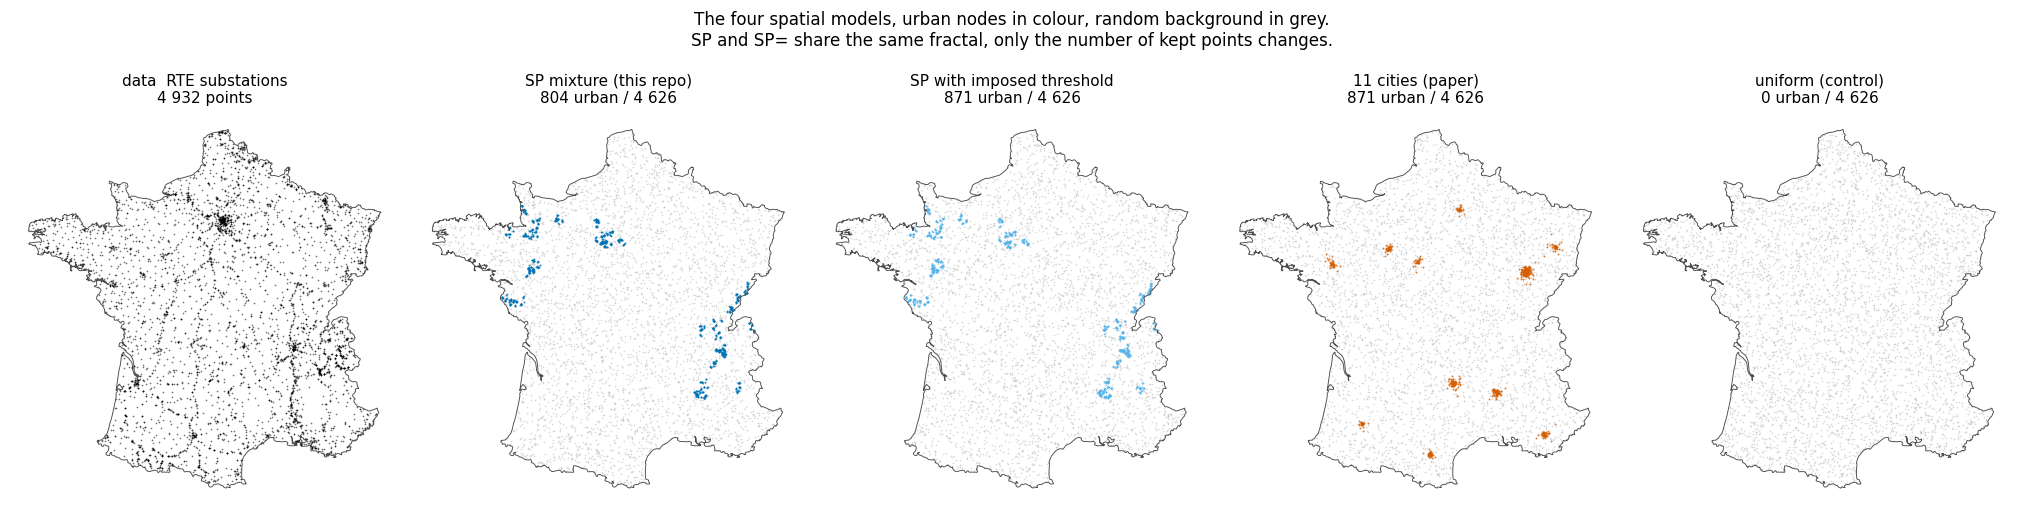

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18.5, 4.4))
bnd = ld["gdf_edge"].boundary

ax = axes[0]
bnd.plot(ax=ax, color="0.3", lw=0.6)
ax.scatter(ld["xy_metric"][:, 0], ld["xy_metric"][:, 1], s=1.2, c=C["rte"], alpha=.55,
           linewidths=0)
ax.set_title(f"data, RTE substations\n{ld['N_real']:,} points".replace(",", " "),
             fontsize=10)

for ax, m in zip(axes[1:], MODELS):
    xy, iu = POS[m][0]
    bnd.plot(ax=ax, color="0.3", lw=0.6)
    ax.scatter(xy[~iu, 0], xy[~iu, 1], s=1.2, c="0.75", alpha=.6, linewidths=0)
    ax.scatter(xy[iu, 0], xy[iu, 1], s=1.6, c=C[m], alpha=.8, linewidths=0)
    ax.set_title(f"{LBL[m]}\n{iu.sum():,} urban / {len(xy):,}".replace(",", " "),
                 fontsize=10)

for ax in axes:
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("The four spatial models, urban nodes in colour, random background in grey.\n"
             "SP and SP= share the same fractal, only the number of kept points changes.",
             fontsize=11, y=1.06)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_clouds.pdf", bbox_inches="tight")
plt.show()

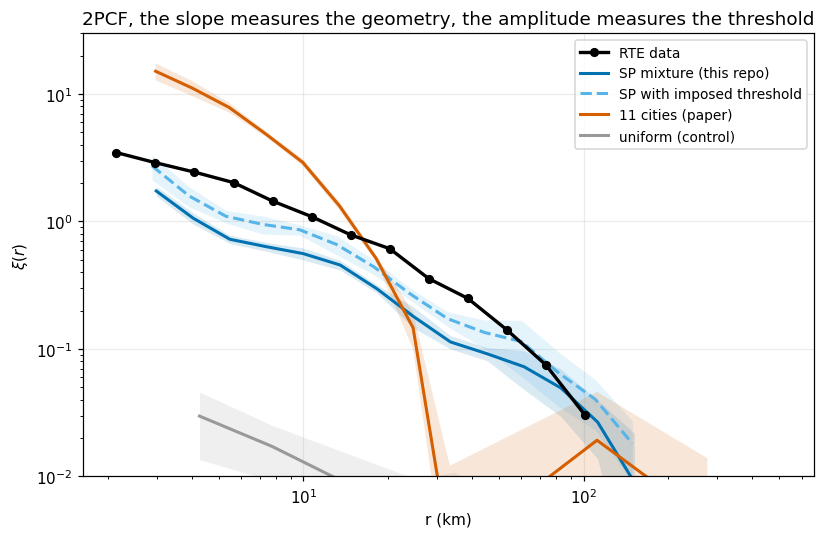

                                   γ    ⟨ξ_mod/ξ_data⟩
SP mixture (this repo)         0.861              0.50
SP with imposed threshold      0.865              0.72
11 cities (paper)              1.869              2.42
uniform (control)              1.160              0.01
RTE data                       0.939              1.00

(ξ ≤ 0 masked: beyond about 100 km the correlation becomes negative for all models, this is the effect of the border of the territory.)


In [7]:
# 2PCF: does the SP mixture reproduce the correlation of the RTE substations?
_cache_pcf = CACHE / f"pcf_models_M{len(MODELS)}.joblib"
if _cache_pcf.exists():
    PCF = joblib.load(_cache_pcf)
else:
    t0 = time.time()
    PCF = {}
    for m in MODELS:
        xis = []
        for s in range(4):
            xy_n, _ = su.normalize_coords(POS[m][s][0], ld["bounds"])
            r_k, xi_k = su.compute_2pcf_norm(xy_n, ld["geom_norm"])
            xis.append(xi_k)
        PCF[m] = (r_k, np.mean(xis, axis=0), np.std(xis, axis=0))
    joblib.dump(PCF, _cache_pcf)
    print(f"(2PCF computed in {time.time()-t0:.0f} s)")

scale_km = ld["scale_m"] / 1e3
fig, ax = plt.subplots(figsize=(7.6, 5.0))
ax.plot(ld["r_data"] * scale_km, np.where(ld["xi_data"] > 0, ld["xi_data"], np.nan),
        "o-", color=C["rte"], lw=2.2, ms=5, label="RTE data", zorder=5)
for m in MODELS:
    r_m, xi_m, xis_m = PCF[m]
    pos = xi_m > 0                          # log scale: ξ ≤ 0 is masked
    ls = "--" if m == "SP20" else "-"
    ax.plot((r_m * scale_km)[pos], xi_m[pos], ls, color=C[m], lw=2, label=LBL[m])
    ax.fill_between((r_m * scale_km)[pos],
                    np.clip(xi_m - xis_m, 1e-3, None)[pos], (xi_m + xis_m)[pos],
                    color=C[m], alpha=.15, lw=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_ylim(1e-2, 3e1)
ax.set_xlabel("r (km)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("2PCF, the slope measures the geometry, the amplitude measures the threshold")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_2pcf.pdf", bbox_inches="tight")
plt.show()

# γ: the shape. <ξ_mod/ξ_data>: the level, on the bins where ξ_data is measurable.
print(f"{'':<28s}{'γ':>8s}{'⟨ξ_mod/ξ_data⟩':>18s}")
for m in MODELS:
    r_m, xi_m, _ = PCF[m]
    g, _ = su.fit_powerlaw_norm(r_m, xi_m)
    xd = np.interp(np.log10(r_m), np.log10(ld["r_data"]),
                   np.nan_to_num(ld["xi_data"]), left=np.nan, right=np.nan)
    sel = np.isfinite(xd) & (xd > 0.05) & (xi_m > 0)
    print(f"{LBL[m]:<28s}{g:>8.3f}{np.mean(xi_m[sel] / xd[sel]):>18.2f}")
print(f"{'RTE data':<28s}{ld['gamma_fit']:>8.3f}{1.0:>18.2f}")
print("\n(ξ ≤ 0 masked: beyond about 100 km the correlation becomes negative for all "
      "models, this is the effect of the border of the territory.)")

**Reading, the slope measures the geometry, the amplitude measures the threshold.**

The SP mixture is the only model that reproduces the correlation of the substations,
**γ = 0.86** against 0.94 for the data. The 11-city model gives **γ = 1.87**. Its 2PCF
does not have the right shape, its clusters are too few and too compact to produce a
power law over three decades. The uniform control, γ = 1.16, only correlates through the
border effect. **This is the only place in the notebook where the models clearly
differ**, keep this contrast in mind for section 6.

Both SP variants share the same fractal tree, and it shows. Their slope is the same
within 0.5 % (**0.861** against **0.865**). What moves is the level, ⟨ξ_mod/ξ_data⟩ goes
from **0.50 to 0.72**, a factor 1.44 for a ratio of fractions (0.200/0.172)² = **1.35**.
The mixture therefore behaves exactly as predicted by ξ_mix = f²·ξ_SP, and **the 2PCF
separates the two questions cleanly**. Its slope constrains the geometry of the clusters,
its amplitude constrains their weight in the cloud. It is the only observable of this
notebook that constrains the threshold. Joule losses, as section 6 shows, are not
sensitive to it at all.

A direct consequence is that **at 20 % of urban nodes, the value of the paper, the SP
mixture stays below the data by a factor 1.4**. Matching ξ_data would require f ≈ 0.24,
about 1 100 structured nodes. This is the same number as the ρ calibration once its
interpolation bias is corrected (√ρ = 0.26 instead of 0.18), so both routes agree. The
true threshold is therefore **above** the 0.2 of the paper, not below as the emergent
0.172 suggested.

The 11-city model does not miss the level but the **shape**, ⟨ξ_mod/ξ_data⟩ = 2.42 with
γ = 1.87. It strongly over-correlates at short range (the 11 blobs) and does not
correlate at all beyond. No threshold setting will bring it closer to the data.

## 4. Growth, unchanged rules, resulting structure

`grow_network` reproduces word for word the rules of `grown_graph_pref_attach_poly`. A
rural node connects to its nearest already placed neighbour, an urban node to the node of
**maximum degree among its `nn_nb = 3` nearest neighbours** (local preferential
attachment), and a **second** edge is added with probability q following the same rule.

One deliberate correction, **all distances are metric**. The code of the paper compares
rural nodes in degrees (lat/lon) and urban nodes in metres, which makes the rural
neighbourhood anisotropic. In France 1° of longitude is worth 0.67° of latitude, so the
rural "nearest neighbour" is biased towards north-south. In the square version
(`grown_graph_pa_flux`, the one that produces the figure of the paper) the problem does
not exist, the coordinates are already in kilometres.

In [8]:
Q_SWEEP = np.array([0.05, 0.15, 0.25, q_RTE, 0.45, 0.5577, 0.70, 0.85])
Q_PAPER = 0.5577          # q of the paper: counts multiple circuits (7 206 circuits)

_cache_net = CACHE / f"networks_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}.joblib"
if _cache_net.exists():
    NETS = joblib.load(_cache_net)
    print("networks: loaded from cache")
else:
    t0 = time.time()
    NETS = {m: {round(float(q), 4): [pg.grow_network(POS[m][s][0], POS[m][s][1],
                                                    float(q), seed=s)
                                     for s in range(N_RUNS)]
                for q in Q_SWEEP}
            for m in MODELS}
    joblib.dump(NETS, _cache_net)
    print(f"networks: {len(MODELS)*len(Q_SWEEP)*N_RUNS} graphs in {time.time()-t0:.0f} s")

qk = round(float(q_RTE), 4)
print(f"\nstructure at q = q_RTE = {q_RTE:.3f}  (mean ± σ over {N_RUNS} draws)")
print(f"{'':<28s}{'L_tot (km)':>18s}{'⟨k⟩':>8s}{'k_max':>8s}"
      f"{'% dead ends':>15s}{'median edge (km)':>18s}")
rows_struct = {}
for m in MODELS:
    Gs = NETS[m][qk]
    L = [pg.total_length_km(G) for G in Gs]
    k = [np.mean([d for _, d in G.degree()]) for G in Gs]
    kmax = [max(d for _, d in G.degree()) for G in Gs]
    dead = [np.mean([d == 1 for _, d in G.degree()]) for G in Gs]
    emed = [np.median([d["length"] for _, _, d in G.edges(data=True)]) / 1e3 for G in Gs]
    rows_struct[m] = dict(L=np.mean(L), Ls=np.std(L), k=np.mean(k), kmax=np.mean(kmax),
                          dead=np.mean(dead), emed=np.mean(emed))
    print(f"{LBL[m]:<28s}{np.mean(L):>11,.0f} ±{np.std(L):>5,.0f}{np.mean(k):>8.2f}"
          f"{np.mean(kmax):>8.0f}{100*np.mean(dead):>14.1f}%{np.mean(emed):>18.1f}"
          .replace(",", " "))
deg_rte = np.array([d for _, d in G_rte.degree()])
elen_rte = np.array([d["length"] for _, _, d in G_rte.edges(data=True)])
rows_struct["RTE"] = dict(L=pg.total_length_km(G_rte), Ls=0.0, k=deg_rte.mean(),
                          kmax=deg_rte.max(), dead=(deg_rte == 1).mean(),
                          emed=np.median(elen_rte) / 1e3)
r = rows_struct["RTE"]
print(f"{'real RTE grid':<28s}{r['L']:>11,.0f}{'':>6s}{r['k']:>8.2f}{r['kmax']:>8.0f}"
      f"{100*r['dead']:>14.1f}%{r['emed']:>18.1f}".replace(",", " "))

networks: loaded from cache

structure at q = q_RTE = 0.356  (mean ± σ over 8 draws)
                                    L_tot (km)     ⟨k⟩   k_max    % dead ends  median edge (km)
SP mixture (this repo)           75 376 ±1 092    2.72      23          29.7%               8.4
SP with imposed threshold        74 612 ±  666    2.72      24          30.1%               8.2
11 cities (paper)                73 459 ±  856    2.72      26          29.9%               8.2
uniform (control)                78 124 ±1 140    2.72      15          26.2%               8.9
real RTE grid                    87 913          2.71      24          29.0%               9.3


In [9]:
# ---------------------------------------------------------------------------
# The "standard growth model" of the paper (fig. 6), over the whole q range.
# It is neither re-implemented nor adapted: `grown_graph_pa_flux` is run as it
# is, and its per-edge losses are taken.
#
# This is needed because the model of the paper carries **three** choices
# locked to each other, which cannot be taken separately:
#   1. injections sorted by node index               (`queue_power.pop()`)
#   2. voltages sorted by creation order              (`queue_voltage.pop()`)
#   3. its own voltage spectrum, regenerated with the proportions
#      taux63/taux90/taux225 on int(N_edges)+1 slots with a 5 sigma margin,
#      so the last 63 kV slots are never popped.
#
# Checked on one realisation at q = 0.5577 (the four numbers below all come
# from the **same** graph, the one of the paper):
#   code of the paper ............................................. 3.753 %
#   dc_losses, sorted P, spectrum of the paper, voltage_rule="time" 3.753 %  ✓
#   dc_losses, sorted P, REAL spectrum (6 272 lines),       "time" . 4.539 %
#   dc_losses, sorted P, spectrum of the paper,             "flow" . 2.174 %
# Taking one queue without the other, or the real spectrum instead of its own,
# changes the result by a factor of about 2, hence the choice to run its code.
# ---------------------------------------------------------------------------
import multiprocessing as mp

_PAPER_NS = {}


def _paper_ns():
    """Namespace of the script of the paper, loaded once per process."""
    if "ns" not in _PAPER_NS:
        scripts = (ROOT / "data" / "tgm" / "scripts").resolve()
        src_ = str((ROOT / "data" / "tgm" / "src").resolve())
        if src_ not in sys.path:
            sys.path.insert(0, src_)
        code = (scripts / "build_energy_estimates.py").read_text().split("Nit = 10")[0]
        cwd = os.getcwd()
        try:
            os.chdir(scripts)
            ns = {"__name__": "not_main"}
            with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), \
                 contextlib.redirect_stderr(dn):
                exec(compile(code, "build_energy_estimates.py", "exec"), ns)
        finally:
            os.chdir(cwd)
        _PAPER_NS["ns"] = ns
    return _PAPER_NS["ns"]


def _paper_one(args):
    """One realisation: per-edge losses, voltage and length of each edge, degrees."""
    import random as _r
    import networkx as nx
    q, seed = args
    ns = _paper_ns()
    _r.seed(seed); np.random.seed(seed)
    with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), \
         contextlib.redirect_stderr(dn):
        G = ns["grown_graph_pa_flux"](p_growth=float(q), preferential_attachment=True)
    Jd = nx.get_edge_attributes(G, "imped_weight_min")
    e = list(Jd)
    return (round(float(q), 4), seed,
            dict(J=np.array([Jd[k] for k in e], dtype=float),
                 U=np.array([G.edges[k]["Voltage"] for k in e], dtype=float),
                 L=np.array([G.edges[k]["length_in_m"] for k in e], dtype=float),
                 deg=np.array([d for _, d in G.degree()], dtype=int)))


_cache_gm = CACHE / "paper_growth_model.joblib"
if _cache_gm.exists():
    PAPER = joblib.load(_cache_gm)
    print("model of the paper: loaded from cache")
else:
    t0 = time.time()
    jobs = [(float(q), s) for q in Q_SWEEP for s in range(N_RUNS)]
    with mp.Pool(min(12, mp.cpu_count())) as pool:      # about 2 min on 12 cores
        PAPER = {(q, s): d for q, s, d in pool.map(_paper_one, jobs, chunksize=1)}
    joblib.dump(PAPER, _cache_gm, compress=3)
    print(f"model of the paper: {len(jobs)} realisations in {time.time()-t0:.0f} s")

# total losses, in % of the installed power, the curve of fig. 6
J_GM = {}
for q in Q_SWEEP:
    k = round(float(q), 4)
    v = [100 * PAPER[(k, s)]["J"].sum() / Ptot for s in range(N_RUNS)]
    J_GM[k] = (float(np.mean(v)), float(np.std(v)))

# check of the port: our `grow_network` ("11 cities" model) against the code of
# the paper, at q = q_RTE, on the structure observables of section 4
_gL = [PAPER[(qk, s)]["L"].sum() / 1e3 for s in range(N_RUNS)]
_gd = [PAPER[(qk, s)]["deg"] for s in range(N_RUNS)]
_ge = [np.median(PAPER[(qk, s)]["L"]) / 1e3 for s in range(N_RUNS)]
print(f"\nport of the 11-city model, our `grow_network` against the code of the paper"
      f"   (q = q_RTE, {N_RUNS} draws)")
print(f"{'':<28s}{'L_tot (km)':>18s}{'⟨k⟩':>8s}{'k_max':>8s}"
      f"{'% dead ends':>15s}{'median edge (km)':>18s}")
r = rows_struct["ORI"]
print(f"{'  re-implementation':<28s}{r['L']:>11,.0f} ±{r['Ls']:>5,.0f}{r['k']:>8.2f}"
      f"{r['kmax']:>8.0f}{100*r['dead']:>14.1f}%{r['emed']:>18.1f}".replace(",", " "))
print(f"{'  code of the paper':<28s}{np.mean(_gL):>11,.0f} ±{np.std(_gL):>5,.0f}"
      f"{np.mean([d.mean() for d in _gd]):>8.2f}{np.mean([d.max() for d in _gd]):>8.0f}"
      f"{100*np.mean([(d == 1).mean() for d in _gd]):>14.1f}%{np.mean(_ge):>18.1f}"
      .replace(",", " "))
print(f"\nlosses of the model of the paper (its code, its two queues):")
print(f"  at q = q_RTE   = {q_RTE:.4f} : {J_GM[qk][0]:.2f} ± {J_GM[qk][1]:.2f} %")
_kp = round(float(Q_PAPER), 4)
print(f"  at q = q paper = {Q_PAPER:.4f} : {J_GM[_kp][0]:.2f} ± {J_GM[_kp][1]:.2f} %"
      f"   (published by RTE: {pg.RTE_PUBLISHED_LOSS_PCT:.2f} %)")

model of the paper: loaded from cache

port of the 11-city model, our `grow_network` against the code of the paper   (q = q_RTE, 8 draws)
                                    L_tot (km)     ⟨k⟩   k_max    % dead ends  median edge (km)
  re-implementation              73 459 ±  856    2.72      26          29.9%               8.2
  code of the paper              73 081 ±  773    2.72      22          29.3%               8.1

losses of the model of the paper (its code, its two queues):
  at q = q_RTE   = 0.3558 : 4.66 ± 0.38 %
  at q = q paper = 0.5577 : 3.47 ± 0.27 %   (published by RTE: 3.38 %)


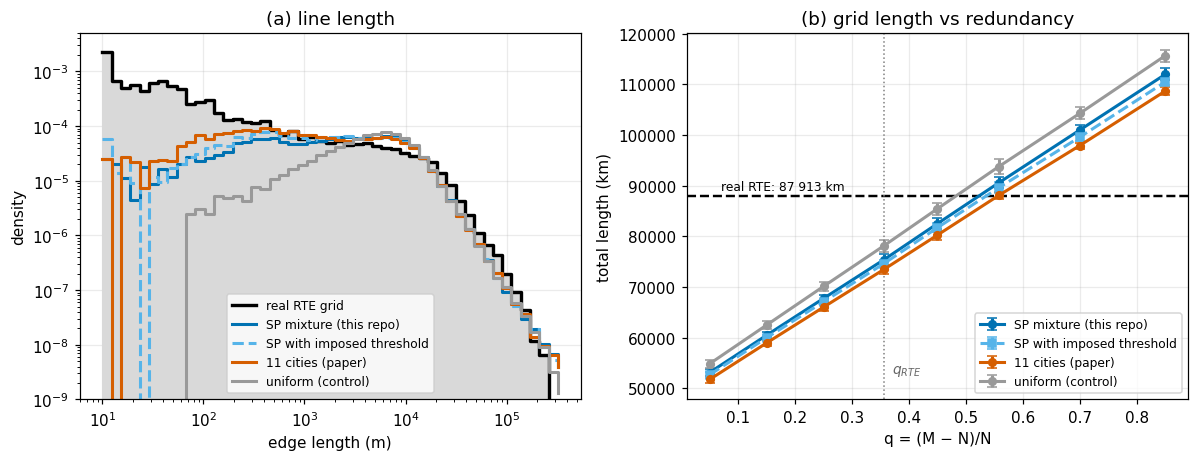

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# (a) edge lengths
ax = axes[0]
lb = np.logspace(1, 5.6, 51); lx = lb[:-1]
ax.fill_between(lx, np.histogram(elen_rte, bins=lb, density=True)[0], 1e-10,
                step="post", color="0.85", lw=0)
ax.step(lx, np.histogram(elen_rte, bins=lb, density=True)[0], where="post",
        color=C["rte"], lw=2.2, label="real RTE grid")
for m in MODELS:
    e = np.concatenate([[d["length"] for _, _, d in G.edges(data=True)]
                        for G in NETS[m][qk]])
    ax.step(lx, np.histogram(e, bins=lb, density=True)[0], where="post",
            color=C[m], lw=2, ls="--" if m == "SP20" else "-", label=LBL[m])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-9, 5e-3)
ax.set_xlabel("edge length (m)"); ax.set_ylabel("density")
ax.set_title("(a) line length"); ax.legend(fontsize=8)

# (b) total length vs q
ax = axes[1]
for m in MODELS:
    st = [[pg.total_length_km(G) for G in NETS[m][round(float(q), 4)]] for q in Q_SWEEP]
    ax.errorbar(Q_SWEEP, [np.mean(v) for v in st], yerr=[np.std(v) for v in st],
                fmt="s--" if m == "SP20" else "o-", color=C[m], lw=2, ms=5, capsize=3,
                label=LBL[m])
L_rte = pg.total_length_km(G_rte)
ax.axhline(L_rte, color=C["rte"], lw=1.6, ls="--")
ax.annotate(f"real RTE: {L_rte:,.0f} km".replace(",", " "), xy=(0.07, L_rte),
            xytext=(0.07, L_rte * 1.015), fontsize=8, color=C["rte"])
ax.axvline(q_RTE, color="0.5", lw=1, ls=":")
ax.annotate("$q_{RTE}$", xy=(q_RTE, 5.3e4), xytext=(q_RTE + .015, 5.3e4), fontsize=9,
            color="0.4")
ax.set_xlabel("q = (M − N)/N"); ax.set_ylabel("total length (km)")
ax.set_title("(b) grid length vs redundancy"); ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
fig.savefig(ROOT / "out" / "06_topology.pdf", bbox_inches="tight")
plt.show()

**Reading.** The four models produce the same topology at first order, as expected,
since the connection rules are identical and q is imposed. The table above gives the
numbers, mean degree 2.72 against 2.71 for RTE, median edge length 8.2-8.9 km against
9.3 km, fraction of dead ends 29.7-30.1 % against 29.0 %. **The degree distribution
deserves more than a panel.** It is set at first order by q and by the connection rule,
the four models look very similar, and the eye cannot decide. Section 4.1 tests it
quantitatively, it is the only topological observable of the notebook that separates
"with clusters" from "without clusters". The only visible trace of the urban structure
here is the maximum degree (23 / 24 / 26 for the three clustered models and 24 for RTE,
against 15 for the control). Preferential attachment only acts on urban nodes, so
without them there is no hub. The two panels drawn here are therefore both about
**lengths**.

**Panel (a) carries the information.** All models under-produce very short links.
**13.3 %** of the RTE lines are shorter than one kilometre, against 7.4 % for the 11
cities, 5.9 % for SP=, 4.7 % for SP and **1.0 %** for the uniform control. The order
follows exactly the degree of clustering of the models, and **the real grid is more
clustered than all of them**. This is the same message as the 2PCF amplitude in
section 3, read on another observable. Long links are well reproduced (2.0-2.1 % beyond
50 km against 3.6 % for RTE).

**Panel (b), total length.** It is about 14 % below RTE at q_RTE (75 400 km for SP,
74 600 for SP=, 73 500 for the 11 cities, 78 100 for the control, against 87 900). It
grows linearly with q and crosses the real value at q = 0.52 / 0.53 / 0.56 / 0.48, that
is, around the q = 0.56 of the paper, which counts multiple circuits. This is consistent
with the published length adding up doubled links that the model represents by a single
edge. The uniform control is always the longest (no clusters, so longer
nearest-neighbour jumps), which will weigh on its losses in section 6.

### 4.1 Test on the degree distributions

The table of section 4 compares means. It does not say whether the degree
*distributions* differ, nor by how much. Here we test the five topologies against each
other and against RTE, on P(k) truncated at k ≥ 9.

The difficulty is that N = 4 626. At this size, any goodness-of-fit test rejects
everything. The χ² is therefore not the useful information, it is given for reference.
What matters is the **effect size relative to the model's own noise**:

- **total variation** distance TV(P, Q) = ½ Σ_k |P(k) − Q(k)|, bounded by 1 and readable
  directly as "the fraction of nodes that would have to move from one degree class to
  another",
- **noise floor**, the mean TV between two draws *of the same* model (28 pairs). This is
  the natural unit. A gap to the real grid of 7 times the floor is massive, a gap between
  two models of 1 times the floor means they are indistinguishable.

The model of the paper is included as it is (its own code), which also tests the
re-implementation of the growth rule used for the four others.

degree distribution P(k), in % of the nodes   (q = q_RTE, 8 draws)

                                      1      2      3      4      5      6      7      8     ≥9     ⟨k⟩
SP mixture (this repo)             29.7   29.5   16.8   10.0    5.8    3.4    1.9    1.0    2.0    2.72
SP with imposed threshold          30.1   29.6   16.5    9.7    5.8    3.2    1.9    1.1    2.1    2.72
11 cities (paper)                  29.9   29.5   16.9    9.8    5.5    3.5    2.0    1.2    1.8    2.72
uniform (control)                  26.2   30.5   18.3   11.2    6.3    3.4    1.9    0.9    1.2    2.72
standard growth model (paper)      29.3   29.5   17.0   10.1    5.9    3.4    1.9    1.0    1.9    2.72
real RTE                           29.0   30.4   25.2    4.8    2.5    1.6    1.6    1.4    3.5    2.71

                                    TV(model, RTE)  intra noise     ratio   χ² (9 dof)          p
SP mixture (this repo)               0.1135 ±0.0050       0.0161      7.0×          614   1.8e-126
SP wit

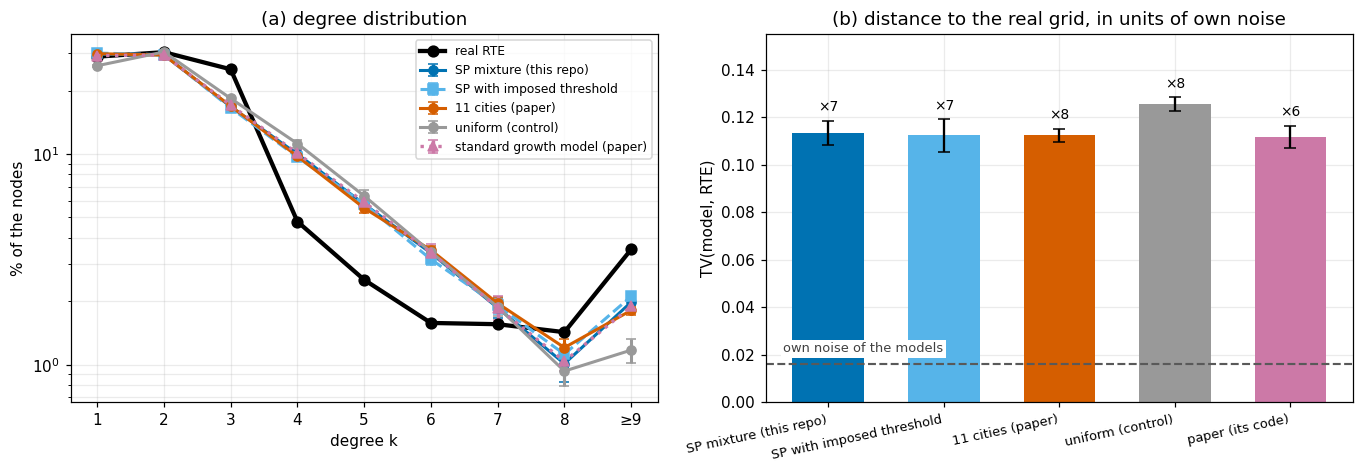

In [11]:
import itertools
from scipy import stats

KMAX = 9                                   # classes 1, 2, … 8, ≥9
KLAB = [str(k) for k in range(1, KMAX)] + [f"≥{KMAX}"]


def deg_pmf(deg):
    d = np.clip(np.asarray(deg), 1, KMAX)
    return np.bincount(d, minlength=KMAX + 1)[1:].astype(float) / len(d)


def tv(a, b):
    """Total variation distance between two discrete distributions."""
    return 0.5 * np.abs(a - b).sum()


DEG = {m: [np.array([d for _, d in G.degree()]) for G in NETS[m][qk]] for m in MODELS}
DEG["GM"] = [PAPER[(qk, s)]["deg"] for s in range(N_RUNS)]
DEG["RTE"] = [np.array([d for _, d in G_rte.degree()])]
PK = {k: np.array([deg_pmf(d) for d in v]) for k, v in DEG.items()}
DKEYS = list(MODELS) + ["GM"]
DLBL = dict(LBL, GM="standard growth model (paper)", RTE="real RTE")
C["GM"] = C["warn"]        # the model of the paper: Okabe-Ito pink, black stays for RTE

print(f"degree distribution P(k), in % of the nodes   (q = q_RTE, {N_RUNS} draws)\n")
print(f"{'':<32s}" + "".join(f"{l:>7s}" for l in KLAB) + f"{'⟨k⟩':>8s}")
for k in DKEYS + ["RTE"]:
    mu = PK[k].mean(0)
    print(f"{DLBL[k]:<32s}" + "".join(f"{100*x:>7.1f}" for x in mu)
          + f"{np.mean([d.mean() for d in DEG[k]]):>8.2f}")

# noise floor: TV between two draws of the same model
intra = {m: (lambda v: (np.mean(v), np.std(v)))(
             [tv(PK[m][i], PK[m][j])
              for i, j in itertools.combinations(range(N_RUNS), 2)])
         for m in DKEYS}

print(f"\n{'':<32s}{'TV(model, RTE)':>18s}{'intra noise':>13s}"
      f"{'ratio':>10s}{'χ² (9 dof)':>13s}{'p':>11s}")
n_rte = len(DEG["RTE"][0])
TVR = {}
for m in DKEYS:
    v = [tv(PK[m][i], PK["RTE"][0]) for i in range(N_RUNS)]
    o = np.round(PK[m].mean(0) * n_rte); e = PK["RTE"][0] * n_rte
    G2 = 2 * np.nansum(np.where(o > 0, o * np.log(o / e), 0.0))
    TVR[m] = (np.mean(v), np.std(v))
    print(f"{DLBL[m]:<32s}{np.mean(v):>11.4f} ±{np.std(v):>5.4f}"
          f"{intra[m][0]:>13.4f}{np.mean(v)/intra[m][0]:>9.1f}×"
          f"{G2:>13.0f}{stats.chi2.sf(G2, KMAX):>11.1e}")

print("\nTV between models (mean over the 64 pairs of draws), "
      "to compare with the intra noise ≈ 0.016")
print(f"{'':<32s}" + "".join(f"{m:>9s}" for m in DKEYS))
TVM = {}
for a in DKEYS:
    row = ""
    for b in DKEYS:
        if a == b:
            row += f"{'-':>9s}"; continue
        TVM[(a, b)] = np.mean([tv(PK[a][i], PK[b][j])
                               for i in range(N_RUNS) for j in range(N_RUNS)])
        row += f"{TVM[(a, b)]:>9.4f}"
    print(f"{DLBL[a]:<32s}" + row)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
xs = np.arange(1, KMAX + 1)
for k in DKEYS:
    mu, sd = PK[k].mean(0), PK[k].std(0)
    ax.errorbar(xs, 100 * mu, yerr=100 * sd,
                fmt="s--" if k == "SP20" else ("^:" if k == "GM" else "o-"),
                color=C[k], lw=2.2 if k == "GM" else 2,
                ms=6, capsize=3, label=DLBL[k])
ax.plot(xs, 100 * PK["RTE"][0], "o-", color=C["rte"], lw=2.8, ms=7, label="real RTE")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(KLAB)
ax.set_xlabel("degree k"); ax.set_ylabel("% of the nodes")
ax.set_title("(a) degree distribution"); ax.legend(fontsize=8); ax.grid(alpha=.25, which="both")

ax = axes[1]
xs2 = np.arange(len(DKEYS))
ax.bar(xs2, [TVR[m][0] for m in DKEYS], yerr=[TVR[m][1] for m in DKEYS],
       color=[C[m] for m in DKEYS], capsize=4, width=.62)
ax.axhline(np.mean([intra[m][0] for m in DKEYS]), color="0.35", lw=1.4, ls="--")
ax.annotate("own noise of the models",
            xy=(0.03, np.mean([intra[m][0] for m in DKEYS]) + .005),
            xycoords=("axes fraction", "data"), fontsize=8.5, color="0.25",
            bbox=dict(fc="white", ec="none", pad=1.5))
for i, m in enumerate(DKEYS):
    ax.annotate(f"×{TVR[m][0]/intra[m][0]:.0f}", (i, TVR[m][0] + TVR[m][1] + .004),
                ha="center", fontsize=9)
ax.set_xticks(xs2)
ax.set_xticklabels([LBL[m] if m in LBL else "paper (its code)" for m in DKEYS],
                   fontsize=8.5, rotation=12, ha="right")
ax.set_ylim(0, .155); ax.set_ylabel("TV(model, RTE)")
ax.set_title("(b) distance to the real grid, in units of own noise")
ax.grid(alpha=.25, axis="y")

plt.tight_layout()
fig.savefig(ROOT / "out" / "06_degrees.pdf", bbox_inches="tight")
plt.show()

**Reading.**

**The port is validated.** The model of the paper run with *its* code and our 11-city
re-implementation are at **TV = 0.018** from each other, for an own noise of 0.014 to
0.018, so they are indistinguishable at the level of sampling noise. The structure table
of the previous cell says the same (73 100 against 73 500 km, ⟨k⟩ 2.72 on both sides,
29.3 against 29.9 % of dead ends, median edge 8.1 against 8.2 km, only the maximum
degree differs, 22 against 26, but it is a maximum over 4 626 draws). Everything that
follows on the four models therefore also holds for the model of the paper, and
conversely.

**The five models miss RTE in the same way, by far.** TV = 0.112 to 0.126, that is,
**6 to 8 times their own noise**, χ² from 575 to 767 for 9 degrees of freedom,
p < 10⁻¹¹⁸. This is not a marginal gap, **11 to 13 % of the nodes** would have to move
from one degree class to another to go from a model to the data. The gap goes in the same
direction for all of them. The mechanism shows on panel (a).

| | k = 3 | k = 4 | k ≥ 9 |
|---|---|---|---|
| real RTE | **25.2 %** | **4.8 %** | **3.5 %** |
| clustered models | 16.5-17.0 % | 9.7-10.1 % | 1.8-2.1 % |
| uniform control | 18.3 % | 11.2 % | 1.2 % |

The real grid **concentrates** its nodes on degree 3 and empties beyond, with in addition
a handful of very large hubs. The models instead spread a regular decay from k = 3 to
k = 8. This is structural. The growth rule adds a node with **one** edge, plus a second
one with probability q, which produces a geometric distribution in k, whereas the real
grid is an engineered object where the three-feeder substation is the standard pattern.
The degree distribution is not something this family of models can reach by tuning q.

**However, and this is the useful result, it discriminates where Joule losses did not.**
The four clustered models (SP, SP=, 11 cities, paper) are at TV = 0.016 to 0.021 from
each other, **exactly at the noise level**. Neither the fractal geometry, nor the
threshold, nor the number of clusters leaves any trace in P(k). The **uniform control**
departs at TV = 0.043 to 0.052, about **3 times the noise**, a clear and reproducible
effect. This is the first observable of this notebook that cleanly separates "with
clusters" from "without clusters".

**And it separates them in the right direction.** The uniform control is also the
**farthest** from RTE (0.126 against 0.112-0.113). Without clusters, there are too many
nodes of degree 2-4 and no hub at all (1.2 % of k ≥ 9 against 3.5 % in the data).
Clustering therefore pushes P(k) in the right direction. It only covers a tenth of the
way, but it does, measurably. On Joule losses (section 6) the control without cities was
instead *as good* as the clustered models. The two observables do not rank the models
the same way, and the degree distribution is right to separate them.

**What it is worth as a test.** It is one-sided. It rejects all models against the data,
and only separates "clusters / no clusters". To separate cluster geometries, the degree
distribution is blind. Observables mixing topology and distance (section 7) are needed,
or the 2PCF of the positions itself (section 3), which is the only one separating the
four models unambiguously.

## 5. From metadata to injections

The load-flow needs a vector of net injections P_i = production_i − consumption_i, with
zero sum. The paper builds it through a modelling chain (population density assigned to
the nodes, converted into consumption by a law `pop_i ** κ`, completed by a randomly
drawn production). Each link of this chain adds an assumption, and the parameter κ is not
set by any data.

**This notebook does not follow that route.** No metadata is modelled. We take the
**real** injection vector, the one of the 4 626 RTE substations, published, with
production and consumption already matched substation by substation, and we only vary
**the way it is placed on the nodes of the model**. Two placements bracket the question.

| recipe | where the largest injection goes | position ↔ injection coupling |
|---|---|---|
| **sorted P (paper)** | on node 0, then by decreasing value | maximal, and **free** |
| **shuffled P** | anywhere | none |

Σ P is conserved in both cases and the marginal is identical, exact, not modelled. The
**only** variable of the experiment is the coupling.

### Why the rule of the paper is not neutral

`np.sort(P)[::-1]` placed by node index looks like an implementation convention. It is
not one. In a growth model, the index **is** the creation order, and preferential
attachment makes the first nodes the most connected.

> corr(creation index, degree) = **−0.61**. Mean degree **8.7** for the first 100 nodes,
> **5.9** over the first 500, **1.8** beyond the 2 000th.

Sorting the injections by decreasing value therefore puts the 5.4 GW of the largest
producer on a node of degree ~9, and the small injections on leaves. This is a strong
**injection ↔ connectivity** coupling, never stated as an assumption, obtained for free
from the numbering of the nodes.

The control is immediate. Applied to the **real** RTE grid, whose node index is
arbitrary, the same rule gives **6.34 %** of losses, against 3.20 % with the injections
at their true place, and 4.41 % when shuffling them. The rule therefore carries no
physics. It exploits a property of the model that does not exist in the data. This is
exactly what section 6 shows, by comparing it term by term with the neutral placement.

### The chain of the paper, moved to section 8

It is not dropped, it is treated as what it is, an assumption whose cost we measure. Two
remarks about it, measured there:

- **κ = 0 is not "the convention of the data"**, despite the shortcut "uniform load".
  Splitting consumption equally *within each département* gives a staircase with 94
  steps, from 8.9 to 119.1 MW per substation, plus 766 substations at zero, CV = 0.72,
  not a global constant. On the real topology, with production left in place, this
  flattening costs **+0.24 point** of losses (3.20 → 3.44 %).
- The gap stays second order, consistent with var(consumption)/var(production) =
  **0.0084**. Consumption does not even carry 1 % of the variance of P, which is dominated
  by the production tail. This is one more reason to work on the published net vector
  rather than rebuild it.

## 6. The result, Joule losses against redundancy

Everything is in place: four spatial models × eight values of q × eight draws × **two
injection recipes**, with **the same** estimator, **the same** voltage spectrum (the
6 272 real RTE lines assigned by flow rank) and **the same** normalisation as the
reference.

In [12]:
# the same real injection vector, placed in two opposite ways
P_ORDERED = np.sort(ref["P"])[::-1]     # assignment of the paper: by node index

RECIPES = ("ordered", "shuffle")
RLBL = {"ordered": "real P sorted by index, the injection rule of the paper",
        "shuffle": "real P shuffled, random position"}
RSHORT = {"ordered": "P sorted/index", "shuffle": "P shuffled"}


def model_P(m, s, recipe):
    """Injection vector of model `m`, draw `s`, for the given recipe.

    Both recipes carry **exactly the same marginal**, the one of the 4 626
    RTE substations, production and consumption matched substation by
    substation. Only the way it is placed on the nodes changes.

    - `ordered`: the largest injection on node 0, then by decreasing value.
      This is the injection rule of the paper (`queue_power.pop()`, checked
      bit-identical), but with the estimator of the notebook (real spectrum
      of the 6 272 lines and voltages by flow rank). The full model of the
      paper, which adds *its* voltage queue and *its* spectrum, is computed
      separately in section 4 (`J_GM`). In a growth model the index **is**
      the creation order, and preferential attachment makes the first nodes
      the most connected (corr(index, degree) = −0.61, mean degree 8.7 for
      the first 100 against 1.8 beyond the 2 000th). The rule therefore
      creates an injection ↔ connectivity coupling for free.
    - `shuffle`: random permutation, no coupling.

    Neither introduces modelled metadata. The population → load chain of the
    paper is measured separately in section 8.
    """
    if recipe == "shuffle":
        return pg.injections_shuffled(ref["P"], seed=s)
    return P_ORDERED


_cache_j = CACHE / (f"joule_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}_"
                    + "-".join(RECIPES) + ".joblib")
if _cache_j.exists():
    JOULE = joblib.load(_cache_j)
    print("losses: loaded from cache")
else:
    t0 = time.time()
    JOULE = {}
    for rc in RECIPES:
        for m in MODELS:
            for q in Q_SWEEP:
                k = round(float(q), 4)
                v = [pg.loss_pct(NETS[m][k][s], model_P(m, s, rc), Ptot, ref["volt_mix"])
                     for s in range(N_RUNS)]
                JOULE[(rc, m, k)] = (np.mean(v), np.std(v))
    joblib.dump(JOULE, _cache_j)
    print(f"losses: {len(RECIPES)*len(MODELS)*len(Q_SWEEP)*N_RUNS} load-flows "
          f"in {time.time()-t0:.0f} s")

# references: the real topology, with exactly the same injection recipe
_cache_r = CACHE / ("ref_losses_" + "-".join(RECIPES) + ".joblib")
if _cache_r.exists():
    REF_L = joblib.load(_cache_r)
else:
    REF_L = {}
    REF_L["given"] = pg.loss_pct(G_rte, ref["P"], Ptot, ref["volt_mix"],
                                 voltage_rule="given")
    REF_L["flow"] = pg.loss_pct(G_rte, ref["P"], Ptot, ref["volt_mix"])
    for rc in RECIPES:
        # the "sorted" reference is the decisive control. On the real grid the
        # node index means nothing, so the rule of the paper has no physical
        # meaning there, and we measure what it gives anyway
        if rc == "shuffle":
            Ps = [pg.injections_shuffled(ref["P"], seed=s) for s in range(N_RUNS)]
        else:
            Ps = [P_ORDERED]
        v = [pg.loss_pct(G_rte, P, Ptot, ref["volt_mix"]) for P in Ps]
        REF_L[rc] = (np.mean(v), np.std(v))
    joblib.dump(REF_L, _cache_r)

print("\nreferences (real RTE topology)")
print(f"  real injections IN PLACE, real voltages      : {REF_L['given']:.2f} %")
print(f"  real injections IN PLACE, voltages by flow   : {REF_L['flow']:.2f} %")
for rc in RECIPES:
    print(f"  recipe '{RSHORT[rc]:<14s}', voltages by flow : "
          f"{REF_L[rc][0]:.2f} ± {REF_L[rc][1]:.2f} %")
print(f"  published by RTE                             : "
      f"{pg.RTE_PUBLISHED_LOSS_PCT:.2f} %")

losses: loaded from cache

references (real RTE topology)
  real injections IN PLACE, real voltages      : 4.74 %
  real injections IN PLACE, voltages by flow   : 3.20 %
  recipe 'P sorted/index', voltages by flow : 6.34 ± 0.00 %
  recipe 'P shuffled    ', voltages by flow : 4.41 ± 0.57 %
  published by RTE                             : 3.38 %


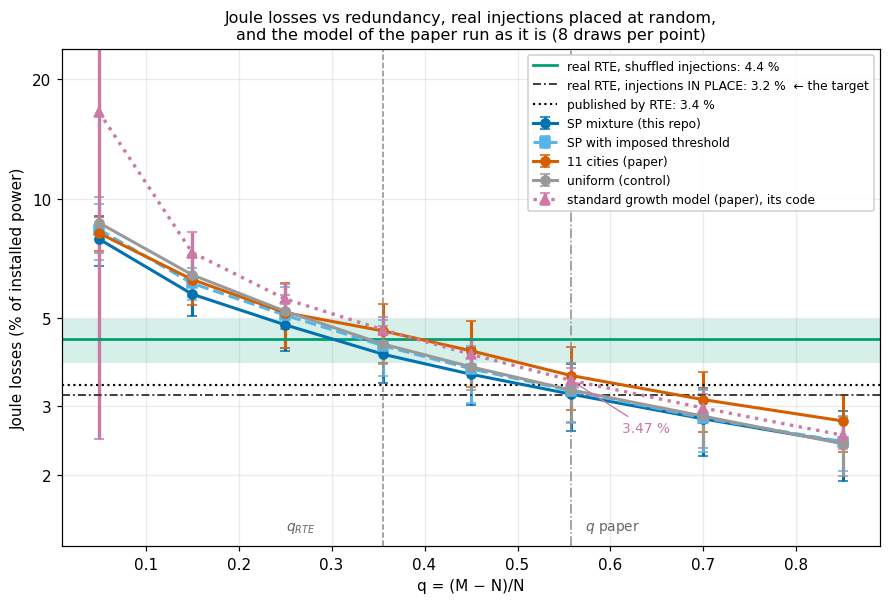

In [13]:
import matplotlib.ticker as mticker

RC_MAIN = "shuffle"          # the recipe of the notebook: real vector, neutral placement
vals = np.array([JOULE[(rc, m, round(float(q), 4))][0]
                 for rc in RECIPES for m in MODELS for q in Q_SWEEP]
                + [J_GM[round(float(q), 4)][0] for q in Q_SWEEP])
ylo, yhi = 0.75 * vals.min(), 1.45 * vals.max()
ticks = [t for t in (1, 2, 3, 5, 10, 20, 40, 80, 160) if ylo <= t <= yhi]


def _yerr(mu, sd):
    """Error bars clipped from below, the axis is logarithmic."""
    return np.vstack([np.minimum(sd, 0.85 * mu), sd])


fig, ax = plt.subplots(figsize=(8.2, 5.6))
mu_r, sd_r = REF_L[RC_MAIN]
ax.axhspan(mu_r - sd_r, mu_r + sd_r, color=C["ref"], alpha=.16, lw=0)

for m in MODELS:
    v = np.array([JOULE[(RC_MAIN, m, round(float(q), 4))] for q in Q_SWEEP])
    ax.errorbar(Q_SWEEP, v[:, 0], yerr=_yerr(v[:, 0], v[:, 1]),
                fmt="s--" if m == "SP20" else "o-",
                color=C[m], lw=2, ms=6, capsize=3, label=LBL[m])

# The standard growth model of the paper (fig. 6), as it is: its code, its
# injections sorted by node index, its voltages sorted by creation order, its
# own voltage spectrum. The three choices are locked together (see section 4),
# none can be taken without the others, so nothing is taken apart and we plot
# what the paper plots.
v = np.array([J_GM[round(float(q), 4)] for q in Q_SWEEP])
ax.errorbar(Q_SWEEP, v[:, 0], yerr=_yerr(v[:, 0], v[:, 1]), fmt="^:", color=C["warn"],
            lw=2.2, ms=7, capsize=3,
            label="standard growth model (paper), its code")

# the three horizontal references, in the legend rather than annotated
ax.axhline(mu_r, color=C["ref"], lw=1.8,
           label=f"real RTE, shuffled injections: {mu_r:.1f} %")
ax.axhline(REF_L["flow"], color="0.25", lw=1.3, ls=(0, (4, 1.5, 1, 1.5)),
           label=f"real RTE, injections IN PLACE: {REF_L['flow']:.1f} %  ← the target")
ax.axhline(pg.RTE_PUBLISHED_LOSS_PCT, color=C["rte"], lw=1.4, ls=":",
           label=f"published by RTE: {pg.RTE_PUBLISHED_LOSS_PCT:.1f} %")

ax.axvline(q_RTE, color="0.55", lw=1, ls="--")
ax.axvline(Q_PAPER, color="0.55", lw=1, ls="-.")
ax.set_yscale("log"); ax.set_ylim(ylo, yhi)
ax.yaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("q = (M − N)/N")
ax.set_ylabel("Joule losses (% of installed power)")
ax.grid(alpha=.25, which="both")
# labels of the vertical lines at the bottom (empty area)
ax.annotate("$q_{RTE}$", xy=(q_RTE, ylo * 1.10), xytext=(q_RTE - .105, ylo * 1.10),
            fontsize=9, color="0.4")
ax.annotate("$q$ paper", xy=(Q_PAPER, ylo * 1.10), xytext=(Q_PAPER + .015, ylo * 1.10),
            fontsize=9, color="0.4")
# the point on which the agreement of the paper rests
_kp = round(float(Q_PAPER), 4)
ax.annotate(f"{J_GM[_kp][0]:.2f} %", xy=(Q_PAPER, J_GM[_kp][0]),
            xytext=(Q_PAPER + .055, J_GM[_kp][0] * 0.74), fontsize=9,
            color=C["warn"],
            arrowprops=dict(arrowstyle="->", color=C["warn"], lw=.9))
ax.legend(fontsize=8, loc="upper right", framealpha=.93)
ax.set_title("Joule losses vs redundancy, real injections placed at random,\n"
             f"and the model of the paper run as it is ({N_RUNS} draws per point)",
             fontsize=10.5)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_joule_vs_q.pdf", bbox_inches="tight")
plt.show()

In [14]:
print(f"Joule losses at q = q_RTE = {q_RTE:.3f}   (% of installed power)\n")
print(f"{'':<28s}{'n_urban':>11s}" + "".join(f"{RSHORT[rc]:>18s}" for rc in RECIPES))
for m in MODELS:
    nu = np.mean([iu.sum() for _, iu in POS[m]])
    line = f"{LBL[m]:<28s}{nu:>11.0f}"
    for rc in RECIPES:
        mu, sd = JOULE[(rc, m, qk)]
        line += f"{mu:>11.2f} ±{sd:>5.2f}"
    print(line)
print("-" * (39 + 18 * len(RECIPES)))
line = f"{'real RTE topology':<28s}{'-':>11s}"
for rc in RECIPES:
    line += f"{REF_L[rc][0]:>11.2f} ±{REF_L[rc][1]:>5.2f}"
print(line + "   ← the reference")
print(f"{'  (injections in place)':<28s}{'-':>11s}{REF_L['flow']:>11.2f}")
print(f"{'  (published by RTE)':<28s}{'-':>11s}{pg.RTE_PUBLISHED_LOSS_PCT:>11.2f}")

print(f"\nstandard growth model of the paper, its code, its two queues, its spectrum")
print(f"  at q = q_RTE   = {q_RTE:.4f} : {J_GM[qk][0]:>5.2f} ± {J_GM[qk][1]:.2f} %"
      f"   ({(J_GM[qk][0]-pg.RTE_PUBLISHED_LOSS_PCT)/pg.RTE_PUBLISHED_LOSS_PCT:+.0%} "
      f"against the published value)")
_kp = round(float(Q_PAPER), 4)
print(f"  at q = q paper = {Q_PAPER:.4f} : {J_GM[_kp][0]:>5.2f} ± {J_GM[_kp][1]:.2f} %"
      f"   ({(J_GM[_kp][0]-pg.RTE_PUBLISHED_LOSS_PCT)/pg.RTE_PUBLISHED_LOSS_PCT:+.0%})"
      f"   ← the agreement of fig. 6")

print("\ngap to the real grid under the same recipe, in units of σ:")
for rc in RECIPES:
    mu_r, sd_r = REF_L[rc]
    line = f"  {RSHORT[rc]:<14s}: "
    for m in MODELS:
        mu, sd = JOULE[(rc, m, qk)]
        line += f"{m} {(mu - mu_r) / np.hypot(sd, sd_r):+.1f}σ   "
    print(line)

print("\neffect of the threshold, same fractal geometry (SP= against SP):")
for rc in RECIPES:
    a, b = JOULE[(rc, "SP", qk)], JOULE[(rc, "SP20", qk)]
    print(f"  {RSHORT[rc]:<14s}: {b[0]-a[0]:+.2f} pt  "
          f"({(b[0]-a[0])/np.hypot(a[1], b[1]):+.1f}σ)")
print("\neffect of the geometry, same number of urban nodes (SP= against 11 cities):")
for rc in RECIPES:
    a, b = JOULE[(rc, "ORI", qk)], JOULE[(rc, "SP20", qk)]
    print(f"  {RSHORT[rc]:<14s}: {b[0]-a[0]:+.2f} pt  "
          f"({(b[0]-a[0])/np.hypot(a[1], b[1]):+.1f}σ)")

Joule losses at q = q_RTE = 0.356   (% of installed power)

                                n_urban    P sorted/index        P shuffled
SP mixture (this repo)              796       3.44 ± 0.61       4.04 ± 0.63
SP with imposed threshold           923       3.06 ± 0.56       4.25 ± 0.67
11 cities (paper)                   923       3.12 ± 0.39       4.63 ± 0.79
uniform (control)                     0       3.49 ± 0.51       4.29 ± 0.48
---------------------------------------------------------------------------
real RTE topology                     -       6.34 ± 0.00       4.41 ± 0.57   ← the reference
  (injections in place)               -       3.20
  (published by RTE)                  -       3.38

standard growth model of the paper, its code, its two queues, its spectrum
  at q = q_RTE   = 0.3558 :  4.66 ± 0.38 %   (+38% against the published value)
  at q = q paper = 0.5577 :  3.47 ± 0.27 %   (+3%)   ← the agreement of fig. 6

gap to the real grid under the same recipe, in units

**What the figure says.** The four models are drawn with the **neutral placement**, the
real injection vector randomly permuted. The pink dotted curve is the **standard growth
model of the paper** (fig. 6), obtained by running its code, without taking anything from
it or imposing anything on it (its injections sorted by index, its voltages sorted by
creation order, its own spectrum). The table above adds, for the four models, what the
**assignment rule of the paper with the estimator of the notebook** gives (real spectrum,
voltages by flow rank). This is a different object from the pink curve, and comparing
the two is the core of what follows.

**The curve of the paper recovers the RTE value, at q = 0.5577.** The model of the paper
gives **3.47 ± 0.27 %** at its own q, against **3.38 %** published, +3 %, so the agreement
of fig. 6 is reproduced. But at **q_RTE = 0.3558**, the q of the topology actually
provided by RTE, the same model gives **4.66 ± 0.38 %**, that is, **+38 %**. Between the
two values of q the curve loses a third of its value, and crosses the published value
around q ≈ 0.58. The agreement therefore does not come from the model alone. It comes
from the convention that counts the **7 206 circuits** rather than the 6 272 lines of the
graph. This convention can be defended (the model creates one edge per circuit), but it
accounts for the whole gap by itself, and it has to be stated.

**The most instructive point, the two queues of the paper almost exactly cancel.** On
the *same* "11 cities" topology, at q_RTE:

| recipe | losses |
|---|---|
| injections sorted by index + voltages by flow rank | **3.12 ± 0.39 %** |
| shuffled injections + voltages by flow rank | **4.63 ± 0.79 %** |
| the paper: sorted injections + voltages by creation order + its spectrum | **4.66 ± 0.38 %** |

Sorting the injections gains **1.5 point** (section 5), and assigning the voltages by
creation order loses **1.5 point** again. The result of the paper is therefore, up to
noise, the one we would get by **shuffling** the injections and sizing the voltages
correctly. The two "tricks" of the model are each off by a factor ~1.5, in opposite
directions, and the total comes out right. This is exactly why total losses are a poor
validation observable, and why section 7 looks at *where* these losses are.

**With the neutral placement, losses do not distinguish any model.** At q_RTE: SP
4.04 ± 0.63 %, SP= 4.25 ± 0.67 %, 11 cities 4.63 ± 0.79 %, uniform control
4.29 ± 0.48 %, against **4.41 ± 0.57 %** for the real topology under the same recipe,
that is, **−0.4σ, −0.2σ, +0.2σ and −0.2σ**. The four are within a whisker of each other,
**and the control without any city is the second closest to the reference**. At fixed N
and q, the level of losses is driven by the total length of the grid and by redundancy,
not by urban geography. This is what the `RAND` control is there to reveal. The paper,
which does not include it, attributes to its rural/urban differentiation an agreement
that a geometry without any city reaches just as well.

**Sorting the injections is not physical.** The control is in the table. The rule
applied to the **real** RTE grid, whose node index is arbitrary, gives **6.34 %**, twice
the right value, and worse than the random placement (4.41 %). It only works where the
index carries information, in a growth model, where it **is** the creation order and
where preferential attachment makes the first nodes the most connected (corr(index,
degree) = −0.61, mean degree 8.7 for the first 100 nodes, 1.8 beyond the 2 000th).
`np.sort(P)[::-1]` puts the 5.4 GW of the largest producer on a hub and the small
injections on leaves. With this rule and a correct estimator, the four models go down to
3.44 / 3.06 / 3.12 / **3.49 %**, against 3.20 % for the real topology with its real
injections in place. The agreement becomes excellent, **and it is just as good for the
model without any city**.

**Neither the number of clusters nor their shape is visible, in either recipe.** With the
same fractal geometry, going from 796 to 923 structured nodes (+16 %) moves the losses by
**−0.5σ / +0.2σ**. With the same number of urban nodes, replacing the self-similar
fractal by the 11 Gaussians of the paper gives **−0.1σ / −0.4σ**. Neither effect reaches
0.5σ. Section 3 nevertheless separated the models unambiguously (γ = 0.86 / 0.87 / 1.87 /
1.16 against 0.94), and section 4.1 separates "with clusters" from "without clusters" at
3 times the noise, where losses separate nothing. The observables do not measure the same
thing, and the least physical of the three is the one that constrains the spatial model
the least.

**The real coupling, on the other hand, can be measured.** On the *real* topology, with
the *real* injection vector, losses are **3.20 %** when each substation keeps its own
injection, and **4.41 ± 0.57 %** when the same vector is randomly permuted. The position ↔
injection coupling is therefore worth **1.2 point of losses, or +38 %**. This is the order
of magnitude the rule of the paper recovers, but through a mechanism that is not the one
of the data. In the model the large injections sit on the most **connected** nodes,
whereas in the data they are where they are for geographical and historical reasons.

**Decrease with q.** Losses drop by a factor 3 to 4 between q = 0.05 and q = 0.85 (SP:
7.0 % → 2.1 % sorted, 7.9 % → 2.4 % shuffled, the model of the paper: 16.5 % → 2.5 %).
Meshing the grid opens parallel paths, each line carries less flow, and J ∝ P². The slope
is the same for all models, one more sign that this observable measures redundancy, not
geography. Note also that at q = 0.56 the models carry **13 % more lines** than the real
grid. The comparison at given topology only makes sense at q = q_RTE.

## 7. Where are the losses?

The total does not tell everything. Two grids can lose the same 4 % while placing the
losses at completely different places. Since `dc_losses` returns the loss **of each
edge**, and the code of the paper returns its own (`imped_weight_min`), we can look at
the *distribution* rather than the sum. The paper does not use this observable.

Three breakdowns, all invariant under node renumbering, hence comparable between
different geometries:

- **(a) concentration**, the Lorenz curve of the losses per line: which fraction of the
  losses is carried by the most loaded lines. Summarised by the Gini coefficient.
- **(b) by voltage level**. For the four models of the notebook, the spectrum of the
  6 272 RTE voltages is imposed identically, so the comparison is direct. **The model of
  the paper is the exception**. It regenerates its own four-level spectrum and assigns it
  by edge creation order (section 4), and these two choices are part of the model. We
  keep them, but its curve (b) answers a slightly different question from the others.
- **(c) by line length**. Losses are R·P²/U² with R ∝ ℓ, so this is where the structural
  difference seen in section 4 (the models under-produce short links) should show up, or
  not.

Recipe: the neutral placement of section 6 for the four models, the model of the paper
run as it is, and the real grid with its real injections as the target. Two controls
complete the picture, the same "11 cities" topology with sorted injections but the
estimator of the notebook, and the "sorted" rule applied to the real grid, where the node
index means nothing.

loss profiles: loaded from cache


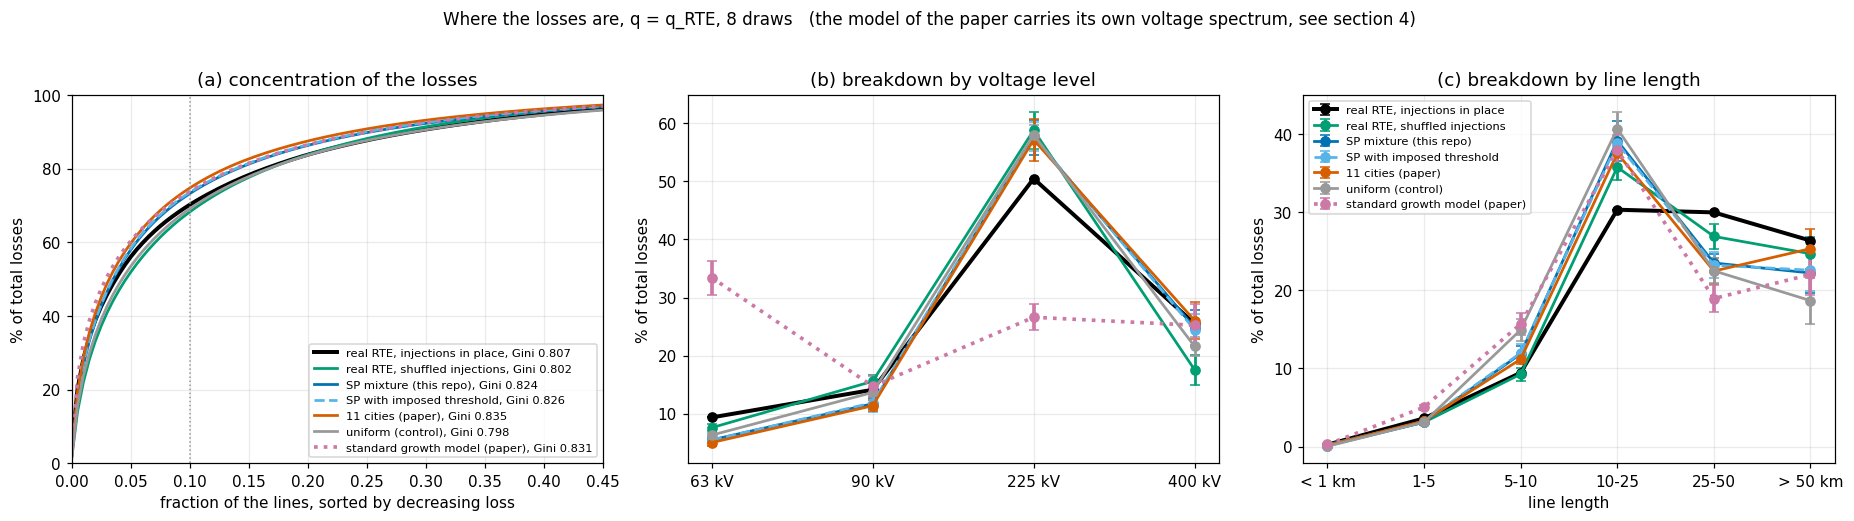

                                     Gini  top 10 %     63 kV     90 kV    225 kV    400 kV   < 1 km      1-5     5-10    10-25    25-50  > 50 km
real RTE, injections in place       0.807     70.2%       9.3      14.1      50.5      25.5      0.3      3.6      9.5     30.3     30.0     26.4
real RTE, shuffled injections       0.802     68.2%       7.6      15.6      58.8      17.6      0.2      3.1      9.3     35.8     26.9     24.7
SP mixture (this repo)              0.824     73.2%       5.5      11.7      57.6      24.8      0.1      3.1     11.9     39.2     23.5     22.2
SP with imposed threshold           0.826     73.5%       5.4      11.9      57.8      24.4      0.1      3.2     12.0     38.8     23.2     22.6
11 cities (paper)                   0.835     74.7%       5.0      11.4      57.2      26.0      0.2      3.3     11.2     37.6     22.5     25.3
uniform (control)                   0.798     69.1%       6.3      13.7      58.0      21.6      0.0      3.1     14.9     4

In [15]:
_cache_lp = CACHE / f"loss_profile_N{N_RTE}_R{N_RUNS}_v3.joblib"
LEV = np.unique(ref["volt_mix"])                      # the 7 real levels, 20 … 400 kV
LBINS = np.array([0, 1e3, 5e3, 1e4, 2.5e4, 5e4, np.inf])
LLAB = ["< 1 km", "1-5", "5-10", "10-25", "25-50", "> 50 km"]
XG = np.linspace(0, 1, 201)                           # common grid for the Lorenz curves


def _snap(U):
    """Map the model voltages (interpolated by quantiles) onto the 7 real levels."""
    return LEV[np.abs(np.log(U[:, None] / LEV[None, :])).argmin(1)]


def _profile(d):
    """Breakdown of the losses of a grid: Lorenz curve, by voltage, by length."""
    J, U, L = d["J"], _snap(d["U"]), d["L"]
    tot = J.sum()
    lor = np.interp(XG, np.arange(1, len(J) + 1) / len(J),
                    np.cumsum(np.sort(J)[::-1]) / tot)
    x = np.sort(J); n = len(J)
    return dict(lor=lor,
                volt=np.array([J[U == v].sum() for v in LEV]) / tot,
                leng=np.array([J[(L >= LBINS[i]) & (L < LBINS[i + 1])].sum()
                               for i in range(len(LLAB))]) / tot,
                gini=float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())),
                top10=float(np.interp(0.10, XG, lor)))


if _cache_lp.exists():
    LP = joblib.load(_cache_lp)
    print("loss profiles: loaded from cache")
else:
    t0 = time.time()
    LP = {m: [_profile(pg.dc_losses(NETS[m][qk][s], model_P(m, s, "shuffle"),
                                    ref["volt_mix"])) for s in range(N_RUNS)]
          for m in MODELS}
    # the model of the paper: its per-edge losses, computed by its own code,
    # hence with ITS voltage spectrum and ITS assignment queue
    LP["GM"] = [_profile(PAPER[(qk, s)]) for s in range(N_RUNS)]
    LP["RTEmix"] = [_profile(pg.dc_losses(G_rte, pg.injections_shuffled(ref["P"], s),
                                          ref["volt_mix"])) for s in range(N_RUNS)]
    LP["RTE"] = [_profile(pg.dc_losses(G_rte, ref["P"], ref["volt_mix"]))]
    # two controls, to separate what comes from the rule from the rest:
    #  - the "sorted" rule on the real grid, whose node index is arbitrary
    LP["RTEord"] = [_profile(pg.dc_losses(G_rte, P_ORDERED, ref["volt_mix"]))]
    #  - the topology of the paper with its sorted injections, but the estimator
    #    of the notebook (real spectrum of the 6 272 lines, voltages by flow rank)
    LP["ORIord"] = [_profile(pg.dc_losses(NETS["ORI"][qk][s], P_ORDERED,
                                          ref["volt_mix"])) for s in range(N_RUNS)]
    joblib.dump(LP, _cache_lp)
    print(f"loss profiles: {time.time()-t0:.0f} s")


def agg(k, f):
    v = np.array([d[f] for d in LP[k]])
    return v.mean(0), v.std(0)


SERIES = [("RTE", "real RTE, injections in place", C["rte"], "-", 2.6),
          ("RTEmix", "real RTE, shuffled injections", C["ref"], "-", 1.8),
          ("SP", LBL["SP"], C["SP"], "-", 1.8),
          ("SP20", LBL["SP20"], C["SP20"], "--", 1.8),
          ("ORI", LBL["ORI"], C["ORI"], "-", 1.8),
          ("RAND", LBL["RAND"], C["RAND"], "-", 1.8),
          ("GM", "standard growth model (paper)", C["warn"], ":", 2.4)]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ax = axes[0]
for k, lab, col, ls, lw in SERIES:
    mu, _ = agg(k, "lor")
    g = np.mean([d["gini"] for d in LP[k]])
    ax.plot(XG, 100 * mu, ls, color=col, lw=lw, label=f"{lab}, Gini {g:.3f}")
ax.axvline(0.10, color="0.6", lw=1, ls=":")
ax.set_xlim(0, 0.45); ax.set_ylim(0, 100)
ax.set_xlabel("fraction of the lines, sorted by decreasing loss")
ax.set_ylabel("% of total losses")
ax.set_title("(a) concentration of the losses"); ax.legend(fontsize=7.5, loc="lower right")
ax.grid(alpha=.25)

ax = axes[1]
keep = [i for i, v in enumerate(LEV) if np.mean([d["volt"][i] for d in LP["RTE"]]) > 0.01]
xs = np.arange(len(keep))
for k, lab, col, ls, lw in SERIES:
    mu, sd = agg(k, "volt")
    ax.errorbar(xs, 100 * mu[keep], yerr=100 * sd[keep], fmt="o" + ls, color=col, lw=lw,
                ms=6, capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels([f"{LEV[i]/1e3:.0f} kV" for i in keep])
ax.set_ylabel("% of total losses")
ax.set_title("(b) breakdown by voltage level"); ax.grid(alpha=.25)

ax = axes[2]
xs = np.arange(len(LLAB))
for k, lab, col, ls, lw in SERIES:
    mu, sd = agg(k, "leng")
    ax.errorbar(xs, 100 * mu, yerr=100 * sd, fmt="o" + ls, color=col, lw=lw, ms=6,
                capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(LLAB)
ax.set_xlabel("line length"); ax.set_ylabel("% of total losses")
ax.set_title("(c) breakdown by line length")
ax.legend(fontsize=7.5, loc="upper left"); ax.grid(alpha=.25)

fig.suptitle("Where the losses are, q = q_RTE, "
             f"{N_RUNS} draws   (the model of the paper carries its own voltage "
             "spectrum, see section 4)", fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_loss_breakdown.pdf", bbox_inches="tight")
plt.show()

TABLE = SERIES + [("ORIord", "11 cities, sorted injections", None, None, None),
                  ("RTEord", "real RTE, sorted injections", None, None, None)]
print(f"{'':<34s}{'Gini':>7s}{'top 10 %':>10s}" + "".join(
    f"{LEV[i]/1e3:>7.0f} kV" for i in keep) + "".join(f"{l:>9s}" for l in LLAB))
for k, lab, *_ in TABLE:
    mu_v, _ = agg(k, "volt"); mu_l, _ = agg(k, "leng")
    print(f"{lab:<34s}{np.mean([d['gini'] for d in LP[k]]):>7.3f}"
          f"{100*np.mean([d['top10'] for d in LP[k]]):>9.1f}%"
          + "".join(f"{100*mu_v[i]:>10.1f}" for i in keep)
          + "".join(f"{100*x:>9.1f}" for x in mu_l))

**Reading.**

**(a) The concentration is the same everywhere, an instructive non-result.** The seven
Lorenz curves overlap. The 10 % most loaded lines carry **68 to 75 %** of the losses,
the real grid included (70.2 %). Gini ranges from 0.798 to 0.835 against **0.807** for
RTE, and the uniform control (0.798) is the closest of all. This extreme concentration is
not a signature of geography. It is what J ∝ P² produces on any meshed grid as soon as
the injections have a heavy tail.

**(b) The voltage level, on the other hand, separates strongly, and it rules out the rule
of the paper.** This is the central result of this section.

| | 63 kV | 90 kV | 225 kV | 400 kV |
|---|---|---|---|---|
| **real RTE, injections in place** | **9.3** | **14.1** | **50.5** | **25.5** |
| standard growth model (paper), its code | **33.4 ± 2.9** | 14.7 | **26.6 ± 2.2** | 25.2 |
| the four models, voltages by flow rank | 5.0-6.3 | 11.4-13.7 | 57.2-58.0 | 21.6-26.0 |
| 11 cities + sorted injections, voltages by flow | 10.2 | 15.9 | 51.1 | 22.4 |

The model of the paper puts **a third of its losses on the 63 kV level**, against 9 % in
the data, and halves its 225 kV share. This is by far the worst profile of the table, and
the cause is identified. Its queue `queue_voltage.pop()` assigns voltages by **edge
creation order**, not according to the flow. At equal flow and length a 63 kV line loses
**175 times** more than a 400 kV line, r(63)/r(400) × (400/63)² = 4.3 × 40.3. Assigning
voltages without looking at the flow leaves real transit on lines that are 175 times more
dissipative, and the bill lands on the 63 kV level. This is "pitfall 2" of section 2.3,
measured here on the loss map rather than on the total. It also explains why the total of
the paper comes out right anyway (section 6, the extra cost of its voltage rule exactly
compensates the gain of its injection rule).

**The same topology, sized correctly, recovers the real profile.** The row "11 cities +
sorted injections, voltages by flow rank" gives **10.2 % / 15.9 % / 51.1 % / 22.4 %**
against **9.3 / 14.1 / 50.5 / 25.5** for the real grid. All four entries match. No other
object of the table comes close. The four models with neutral placement stay at 5-6 % on
the 63 kV level, and the "sorted" rule applied to the **real** grid gives 6.1 % / 62.6 %,
that is, the profile of the neutral placement. It is therefore the **combination** growth
model + sorted injections + voltages by flow that reproduces the voltage breakdown of the
losses, and section 6 gives the mechanism. Sorting the injections puts the large powers
on the most connected nodes, which then receive the high voltages, and leaves the local
traffic on the 63 kV level, as in reality. **This is not the recipe of the paper**, it is
the recipe of the paper corrected for its pitfall 2.

**(c) On lengths, all models fail in the same way, consistent with section 4.** The models
put 37.6 to 40.7 % of the losses on the 10 to 25 km lines (38.0 % for the model of the
paper), against 35.8 ± 1.6 % for the real grid under the same recipe and 30.3 % with its
real injections. They put only 19.0 to 23.5 % on the 25-50 km lines, against 26.9 and
30.0. In other words, **the models lose their energy on lines that are too short**, and
the model of the paper is the worst of the seven in this range (19.0 ± 1.7 %). This is
the energy counterpart of the finding of section 4. Their length distribution is too
narrow, they miss both the very short and the long links. The uniform control, which has
the longest edges on average, is the worst in the 5-10 km range (14.9 ± 1.4 % against
9.5 expected).

**What this changes for the initial question.** This observable is much richer than the
total. It does three things that the scalar did not do. It **rules out a modelling
rule** (the assignment of voltages by creation order, section 2.3, which went unnoticed
because its effect cancelled in the total). It **exhibits a systematic and reproducible
bias** shared by all models (too many losses on lines that are too short). And it shows
that a well-chosen recipe on the same topology **recovers the voltage profile of the real
grid**. However, it still does not **discriminate** between cluster geometries. On the
three breakdowns, a geometry without any city stays as close to the data as the
clustered models. For that, this notebook only has two observables, the 2PCF of the
positions (section 3) and the degree distribution (section 4.1).

## 8. Sensitivities

Four modelling choices remain open. We measure how much each one moves the result, on
the SP model at q = q_RTE, to know how much confidence to put in the main number. This is
also where the **metadata chain of the paper** (population → load ∝ `pop**κ`) is placed,
since section 6 does not use it. We treat it as what it is, an assumption whose cost we
measure.

In [16]:
_cache_s = CACHE / "sensitivity_v4.joblib"

if _cache_s.exists():
    SENS = joblib.load(_cache_s)
else:
    t0 = time.time()
    SENS = {}

    def _P_shuffle(s, model="SP"):
        """The default recipe of the notebook (section 6): real vector, neutral placement."""
        return pg.injections_shuffled(ref["P"], seed=s)

    def _P_load(s, model="SP", **kw):
        """Real load marginal reshuffled, the only one that exposes `prod_where`."""
        _, iu = POS[model][s]
        return pg.injections_marginal_load(ref["P_conso"], prod_pool, Ptot,
                                           seed=s, is_urban=iu, **kw)[0]

    def _P_kappa(s, kappa=0.0, model="SP", **kw):
        """The chain of the paper: assigned population, then load ∝ pop**kappa."""
        _, iu = POS[model][s]
        pop = pg.assign_population(iu, ld["pop_data"], seed=s)
        return pg.injections(pop, prod_pool, Ptot, seed=s, kappa=kappa,
                             is_urban=iu, **kw)[0]

    def _sweep(key, P_of_s, rule="flow", model="SP"):
        v = [pg.loss_pct(NETS[model][qk][s], P_of_s(s), Ptot, ref["volt_mix"],
                         voltage_rule=rule) for s in range(N_RUNS)]
        SENS[key] = (float(np.mean(v)), float(np.std(v)))

    for rule in ("flow", "time", "length", "random"):
        _sweep(("voltage", rule), _P_shuffle, rule=rule)
    for pw in ("random", "rural", "urban"):
        _sweep(("production", pw), lambda s, pw=pw: _P_load(s, prod_where=pw))

    # what modelling the load would cost, instead of taking the published vector
    _sweep(("recipe", "P shuffled"), _P_shuffle)
    _sweep(("recipe", "P sorted"), lambda s: P_ORDERED)
    _sweep(("recipe", "load reshuffled"), _P_load)
    for kappa in (0.0, 0.25, 0.5, 1.0):
        _sweep(("recipe", f"κ = {kappa}"), lambda s, k=kappa: _P_kappa(s, kappa=k))

    # κ = 1 is the only regime where geography becomes visible again, so the other
    # models and the reference are added there, otherwise the comparison has no judge
    for m in ("SP20", "ORI", "RAND"):
        _sweep(("κ = 1: other models", m),
               lambda s, m=m: _P_kappa(s, kappa=1.0, model=m), model=m)
    v = [pg.loss_pct(G_rte, pg.injections(pop_rte, prod_pool, Ptot, seed=s,
                                          kappa=1.0)[0], Ptot, ref["volt_mix"])
         for s in range(N_RUNS)]
    SENS[("κ = 1: other models", "real RTE")] = (float(np.mean(v)), float(np.std(v)))

    # cost of the κ = 0 flattening, measured without any model: real topology,
    # real production in place, only the consumption is replaced
    for lab, P in [("real load in place", ref["P"]),
                   ("flattened to its mean", ref["P_prod"] - ref["P_conso"].mean())]:
        SENS[("κ = 0 flattening", lab)] = (
            float(pg.loss_pct(G_rte, P, Ptot, ref["volt_mix"])), 0.0)

    # the two orderings of the paper, decoupled then coupled again
    _sweep(("ordering", "neutral + flow"), _P_shuffle, rule="flow")
    _sweep(("ordering", "neutral + queue"), _P_shuffle, rule="time")
    _sweep(("ordering", "sorted + flow"), lambda s: P_ORDERED, rule="flow")
    _sweep(("ordering", "sorted + queue"), lambda s: P_ORDERED, rule="time")
    joblib.dump(SENS, _cache_s)
    print(f"(sensitivities computed in {time.time()-t0:.0f} s)")

NOTE = {("voltage", "flow"): "default, sizing by flow",
        ("voltage", "time"): "sorted queue of the paper (creation order)",
        ("voltage", "length"): "longest line = highest voltage",
        ("voltage", "random"): "spectrum kept, correlation destroyed",
        ("production", "random"): "default, plants anywhere",
        ("production", "rural"): "plants in the random background",
        ("production", "urban"): "plants in the SP clusters",
        ("recipe", "P shuffled"): "default of section 6, published vector, neutral placement",
        ("recipe", "P sorted"): "section 6, published vector, assignment of the paper",
        ("recipe", "load reshuffled"): "real load marginal, random production",
        ("recipe", "κ = 0.0"): "chain of the paper, flat load",
        ("recipe", "κ = 0.25"): "",
        ("recipe", "κ = 0.5"): "",
        ("recipe", "κ = 1.0"): "load ∝ population metadata",
        ("κ = 1: other models", "SP20"): "SP with imposed threshold",
        ("κ = 1: other models", "ORI"): "11 cities (paper)",
        ("κ = 1: other models", "RAND"): "uniform control, no city",
        ("κ = 1: other models", "real RTE"): "← the judge",
        ("κ = 0 flattening", "real load in place"): "94 département steps",
        ("κ = 0 flattening", "flattened to its mean"): "what κ = 0 does",
        ("ordering", "neutral + flow"): "default",
        ("ordering", "neutral + queue"): "queue of the paper, unsorted injections",
        ("ordering", "sorted + flow"): "injections sorted as in the paper",
        ("ordering", "sorted + queue"): "both orderings of the paper, locked"}

TITLE = {"voltage": "VOLTAGE", "production": "PRODUCTION", "recipe": "INJECTION RECIPE",
         "κ = 1: other models": "AT κ = 1: THE OTHER MODELS",
         "κ = 0 flattening": "COST OF THE κ = 0 FLATTENING",
         "ordering": "INJECTION ORDERING × VOLTAGE RULE"}
cur = None
for (fam, var), (mu, sd) in SENS.items():
    if fam != cur:
        print(f"  {TITLE[fam]}"); cur = fam
    val = f"{mu:>7.2f} ± {sd:<6.2f}" if sd else f"{mu:>7.2f}        "
    print(f"    {var:<22s} {val}  {NOTE[(fam, var)]}")
print(f"\n  for reference, real RTE topology, default recipe (P shuffled): "
      f"{REF_L['shuffle'][0]:.2f} ± {REF_L['shuffle'][1]:.2f} %")

(sensitivities computed in 14 s)
  VOLTAGE
    flow                      4.04 ± 0.63    default, sizing by flow
    time                     39.07 ± 6.36    sorted queue of the paper (creation order)
    length                   32.56 ± 4.42    longest line = highest voltage
    random                  130.73 ± 18.47   spectrum kept, correlation destroyed
  PRODUCTION
    random                    4.72 ± 1.21    default, plants anywhere
    rural                     6.11 ± 1.61    plants in the random background
    urban                     4.69 ± 0.87    plants in the SP clusters
  INJECTION RECIPE
    P shuffled                4.04 ± 0.63    default of section 6, published vector, neutral placement
    P sorted                  3.44 ± 0.61    section 6, published vector, assignment of the paper
    load reshuffled           4.72 ± 1.21    real load marginal, random production
    κ = 0.0                   4.57 ± 1.21    chain of the paper, flat load
    κ = 0.25                  4.7

**Reading.**

*Voltages dominate everything.* Between "by flow rank" and "at random", the result varies
by a factor 32 (4.0 % against 131 %). This choice is not an implementation detail. It is
the most sensitive parameter of the model, and it must be documented as such.

*The "ordering" block shows that the two rules of the paper hold each other up.* With
neutral injections, the sorted voltage queue gives 39 % against 4.0 % for the flow rule,
a factor 10. But if the injections are also sorted as in the paper, the sorted queue
comes back down to 6.3 % against 3.4 %, a factor 1.8. **The voltage rule is only
acceptable because it shares its index with the injection rule.** This is not a property
of the model, it is a property of the order in which two queues are popped. It disappears
as soon as one of the two is changed, and it has no equivalent on a real grid. Hence the
84 % obtained in section 2.3 by randomly assigning the real RTE spectrum to the real
lines, and the 6.3 % obtained in section 6 by sorting the injections on the real grid.

*The placement of power plants* moves the result by +29 %. Putting production in the rural
background (which is the case of French nuclear plants, located along rivers) makes the
transits longer. This is the most "physical" sensitivity of the set, and it would deserve
a calibration on the real positions of the sites of the national register.

*Modelling the load is costly and brings nothing.* The "recipe" block compares the
published vector (4.0 % shuffled, 3.4 % sorted) with what is obtained by rebuilding it.
Taking only the real consumption marginal gives 4.7 %, flattening it as κ = 0 gives
4.6 %. Consumption does not carry 1 % of the variance of P, so this changes nothing.
But κ then interpolates up to **12.3 %** at κ = 1, through 4.8 and 6.0, with no
threshold, no plateau, and no defensible default value. **This is why section 6 does not
use this chain.** It would add a free parameter worth a factor 3 on the result, to model
a quantity that is published.

*κ = 1 is the only regime of the whole notebook where geography becomes visible again.*
The three clustered models go up to 12.3 / 12.5 / 13.0 % while the uniform control stays
at 6.0 %, a factor two. Grouping the load in tight clusters creates bottlenecks, since all
the consumption of a cluster transits through the few lines that connect it. The real
topology under the same load goes up to 15.7 %, **above** the three clustered models
(−0.9σ, −0.7σ, −0.6σ), while the uniform control is at **−3.1σ**, the only model
excluded in the whole notebook. However, this exclusion rests entirely on κ = 1, that is,
on a proportionality between load and population density that the published data do not
allow us to check. The coupling is then *assumed* instead of measured, and it is the
assumption, not the geometry, that discriminates.

*The κ = 0 flattening can be quantified without any model.* On the real topology, with
production left in place, replacing the 94 département steps by their mean moves the
losses from **3.20 % to 3.44 %**, that is, +0.24 point. This is the exact cost of the
"uniform load" shortcut. It is real, but five times smaller than the cost of the
position ↔ injection decorrelation measured in section 6.

## 9. Conclusion

**The answer to the question: yes, the model gives the right values, but none of the
reasons for this agreement is geographical.**

1. **The SP mixture model gives the right Joule losses.** At q = q_RTE, with the
   injection rule of the paper (real injections sorted by node index) and a correct
   sizing of the voltages, it gives **3.44 ± 0.61 %** of the installed power
   (**3.06 ± 0.56 %** for the imposed-threshold variant), against **3.20 %** for the real
   RTE topology with its real injections in place and **3.38 %** published by RTE.
   Replacing the hand-placed geography by the SP mixture therefore does not break the
   energy behaviour of the growth model.

2. **The model of the paper, run as it is, also recovers the published value, but at its
   own q and through the compensation of two errors.** `grown_graph_pa_flux` gives
   **3.47 ± 0.27 %** at q = 0.5577 against 3.38 % published (+3 %), and
   **4.66 ± 0.38 %** at q_RTE = 0.3558 (+38 %). The agreement rests on the convention that
   counts the 7 206 circuits rather than the 6 272 lines of the graph. It also rests on a
   compensation. On the same "11 cities" topology, at q_RTE, sorted injections + voltages
   by flow give **3.12 %**, shuffled injections + voltages by flow give **4.63 %**, and
   the paper (sorted + voltages by creation order) gives **4.66 %**. Sorting the
   injections gains 1.5 point, assigning the voltages by creation order loses exactly as
   much. Each of the two rules is off by a factor ~1.5, in opposite directions.

3. **And the agreement does not come from geography.** Two controls, each sufficient.
   - The **uniform control**, with zero cities and no structure, gives **3.49 %** under
     the same injection rule, as close to the target as the SP mixture. A geometry
     without any agglomeration reaches the agreement just as well.
   - The same rule applied to the **real RTE grid**, whose node index is arbitrary, gives
     **6.34 %**, twice too much, and worse than the random placement (4.41 %).

   The rule therefore has no physical content. It exploits a property of the growth
   model, in which the index **is** the creation order and preferential attachment makes
   the first nodes the most connected (**corr(index, degree) = −0.61**, mean degree 8.7
   for the first 100 nodes, 1.8 beyond the 2 000th). `np.sort(P)[::-1]` puts the 5.4 GW
   of the largest producer on a hub. **The agreement of the paper with RTE does not
   measure its geography, it measures its node numbering.**

4. **With a neutral placement, losses see nothing of the spatial model.** Same injection
   vector, randomly permuted: SP 4.04, SP= 4.25, 11 cities 4.63, uniform control 4.29 %,
   against **4.41 ± 0.57 %** for the real topology under the same recipe, that is,
   **−0.4σ, −0.2σ, +0.2σ, −0.2σ**, the control without cities being the second closest.
   The two paired contrasts of section 6 go further. With the same geometry, the
   **number** of clusters does not matter (≤ 0.5σ for +16 % of structured nodes). With the
   same number, the **shape** of the clusters does not matter either (≤ 0.4σ). **Joule
   losses are not a discriminating observable for a spatial model**, and this result does
   not rest on any modelled metadata, since both recipes take the published vector as it
   is and only vary its position.

5. **What the models lack is not geometry but coupling, and it can be quantified.** On
   the real topology, with the real injection vector, losses are **3.20 %** in place and
   **4.41 %** permuted. The position ↔ injection coupling is worth **1.2 point, or
   +38 %**. The growth model recovers its value, but through a mechanism that is not the
   one of the data. In the model the large injections sit on the most **connected**
   nodes, whereas in the data they are where they are for geographical and historical
   reasons, hence the 6.34 % when the rule is transported to the real grid. The number is
   right for the wrong reason. This is the common thread of the repository, found again
   on a physical observable. The spatial structure alone is weakly constrained by
   aggregated observables, and it is the **position ↔ metadata coupling** that carries
   the information. This coupling still has to be produced by the model, not simulated by
   a numbering order.

6. **The degree distribution is the only topological observable that discriminates
   (section 4.1).** Tested with the total variation distance, relative to the own noise
   of each model (TV ≈ 0.016 between two draws of the same model), the five models are
   at **TV = 0.112-0.126 from RTE, that is, 6 to 8 times their noise** (χ² 575-767 with
   9 dof, p < 10⁻¹¹⁸). They are all rejected, and in the same way, because a rule "one
   edge, plus a second one with probability q" produces a geometric decay in k, whereas
   the real grid concentrates **25.2 %** of its substations on degree 3 and has only
   4.8 % at degree 4. But the four clustered models are indistinguishable from each other
   (TV 0.016-0.021, the noise), while the **uniform control departs at 3 times the noise**
   (TV 0.043-0.052) and is also the farthest from the data (0.126 against 0.112-0.113).
   Clustering therefore pushes P(k) in the right direction, measurably, where Joule losses
   did not see it at all. The same test also validates the re-implementation of the
   growth rule. Our `grow_network` and the code of the paper are at TV = 0.018 from each
   other, that is, at the noise level.

7. **The breakdown of the losses rules out the voltage assignment rule (section 7).**
   Section 7 splits the losses line by line instead of summing them, and this is where
   the compensation of point 2 comes apart. The model of the paper puts
   **33.4 ± 2.9 %** of its losses on the 63 kV level and **26.6 %** on the 225 kV level,
   against **9.3 %** and **50.5 %** in the data, the worst profile of the seven series.
   The cause is its queue `queue_voltage.pop()`, which assigns voltages by edge creation
   order, whereas at equal flow and length a 63 kV line loses **175 times** more than a
   400 kV line. The same topology with sorted injections and **voltages by flow rank**
   gives instead **10.2 / 15.9 / 51.1 / 22.4 %** against 9.3 / 14.1 / 50.5 / 25.5. All
   four entries match, and nothing else in the table comes close. Two other findings. The
   concentration of the losses is the same everywhere (Gini 0.798-0.835 against 0.807 for
   RTE), it is a property of J ∝ P² and not of geography. And **all** models lose their
   energy on lines that are too short (37.6-40.7 % on the 10-25 km lines against 30.3 %,
   19.0-23.5 % on the 25-50 km lines against 30.0 %), the energy counterpart of the length
   deficit seen in section 4. As in section 6, none of the three breakdowns separates the
   cluster geometries from each other.

8. **On the urban fraction, the claim must be qualified.** Saying that the SP mixture
   "removes a free parameter" by making the urban fraction come out of the calibration
   stays true *in principle*. The 2PCF does constrain the threshold, through its amplitude
   (section 3), where losses are not sensitive to it at all (section 6). But the value
   produced by the code (0.17 ± 0.02) is **biased low**. `build_sp_mixture` interpolates
   ξ_data with `left=0.0`, which counts as zero the bins of the fractal 2PCF below the
   range of the data, and over-dilutes the mixture by a factor ~1.4 in √ρ. The honest
   constraint is f ≈ 0.24, that is, **above** the 0.2 set by the paper. The parameter is
   indeed determined by the data, it is our estimate that must be corrected before being
   reported. The `SP=` variant, which does not use ρ, serves as a control. It gives the
   same losses within 0.5σ, so this bias has no consequence on points 1 to 7.

9. **Four corrections to carry over to the code of the paper.**
   - The susceptance must be **U²/X** and not 1/X. On a multi-voltage grid, the factor is
     3.6 (17 % → 4.7 % on the real topology). The code of the paper does this correctly,
     through the double rescaling by (U_ref/U)², but implicitly, and this is exactly the
     pitfall into which any "clean" re-implementation falls (the one of
     `fake_world/SP_PowerGrid/`, for instance).
   - The voltage assignment must be **explicitly tied to the flow**. This is the
     correction with the heaviest consequences, and it is now shown twice, on the total
     (section 8, 43 % instead of 4.7 % as soon as the two queues are decoupled, 84 % when
     the real RTE spectrum is randomly assigned to the real lines) and on the loss map
     (section 7, a third of the losses on the 63 kV level against 9 % in the data). The
     current sorted queue only works because it shares its index with the injection
     queue, and its error does not show in the total because it compensates the error of
     the injection rule.
   - **The q at which the model is compared must be made explicit.** The agreement of
     fig. 6 is obtained at q = 0.5577, which counts the 7 206 circuits. At q = 0.3558, the
     redundancy of the graph actually published, the same model is 38 % above the RTE
     value. The convention can be defended (the model creates one edge per circuit), but
     it accounts for the whole gap by itself, and the reader must be able to see it.
   - **κ = 0 is not "the convention of the data".** The "uniform load" shortcut confuses
     "split equally within each département" with "constant everywhere". The published
     vector is a staircase with 94 steps, from 8.9 to 119.1 MW per substation, plus 766
     substations at zero (CV = 0.72), not a constant. On the real topology, with
     production in place, the flattening costs +0.24 point (3.20 → 3.44 %). The error has
     no consequence on conclusions 1 to 8, since section 6 does not use κ at all, but the
     label must be corrected, and the absolute level reported is 0.25 point too high.

**Natural next steps.** (i) Points 6 and 7 point to the two observables that *did*
discriminate, the degree distribution, which separates "with clusters" from "without
clusters" but not cluster geometries from each other, and the breakdown of the losses by
voltage, which rules out a modelling rule. Going further in this direction means looking
at betweenness centrality, or at the distribution of flows as a function of the distance
to the nearest cluster, where the cluster structure should leave a signature that the
total length erases. (ii) Points 3 and 5 point to the real target, a model that
*produces* the position ↔ injection coupling through a geographical mechanism, judged on
its ability to recover the 3.2 % **without** relying on the creation order of the nodes.
The test is that the rule survives being transported to the real grid, which the rule of
the paper does not (6.3 %). The sensitivity to the placement of power plants in section 8
(+29 % between rural and random) is the first lever to calibrate, on the real positions of
the sites of the national register. (iii) Replay the protocol on ENEDIS (distribution,
N ≈ 900 000), where the calibrated urban fraction is very different and the meshing is
much weaker.

In [17]:
rows = []
for m in MODELS:
    for rc in RECIPES:
        for q in Q_SWEEP:
            k = round(float(q), 4)
            mu, sd = JOULE[(rc, m, k)]
            Gs = NETS[m][k]
            rows.append(dict(
                model=m, label=LBL[m], recipe=rc, recipe_label=RSHORT[rc],
                q_target=k, q_measured=float(np.mean([pg.q_of(G) for G in Gs])),
                N=N_RTE, n_runs=N_RUNS,
                urban_frac=float(np.mean([iu.mean() for _, iu in POS[m]])),
                n_urban=float(np.mean([iu.sum() for _, iu in POS[m]])),
                L_tot_km=float(np.mean([pg.total_length_km(G) for G in Gs])),
                joule_pct=mu, joule_pct_std=sd))
for q in Q_SWEEP:                     # the model of the paper, run as it is
    k = round(float(q), 4)
    rows.append(dict(
        model="GM", label="standard growth model (paper)", recipe="paper",
        recipe_label="its code, its two queues", q_target=k, q_measured=k,
        N=N_RTE, n_runs=N_RUNS, urban_frac=np.nan, n_urban=np.nan,
        L_tot_km=float(np.mean([PAPER[(k, s_)]["L"].sum() / 1e3
                                for s_ in range(N_RUNS)])),
        joule_pct=J_GM[k][0], joule_pct_std=J_GM[k][1]))
for rc in RECIPES:
    rows.append(dict(model="RTE", label="real RTE topology", recipe=rc,
                     recipe_label=RSHORT[rc], q_target=np.nan, q_measured=q_RTE,
                     N=N_RTE, n_runs=N_RUNS, urban_frac=np.nan, n_urban=np.nan,
                     L_tot_km=pg.total_length_km(G_rte),
                     joule_pct=REF_L[rc][0], joule_pct_std=REF_L[rc][1]))
for lab, val in [("RTE, injections in place, real voltages", REF_L["given"]),
                 ("RTE, injections in place, voltages by flow", REF_L["flow"]),
                 ("value published by RTE", pg.RTE_PUBLISHED_LOSS_PCT)]:
    rows.append(dict(model="RTE", label=lab, recipe="-", recipe_label="-",
                     q_target=np.nan, q_measured=q_RTE, N=N_RTE, n_runs=1,
                     urban_frac=np.nan, n_urban=np.nan,
                     L_tot_km=pg.total_length_km(G_rte),
                     joule_pct=val, joule_pct_std=0.0))

df_out = pd.DataFrame(rows)
df_out.to_csv(ROOT / "out" / "06_powergrid_sp_joule.csv", index=False)

df_sens = pd.DataFrame([dict(family=f, variant=v, joule_pct=mu, joule_pct_std=sd,
                             note=NOTE[(f, v)])
                        for (f, v), (mu, sd) in SENS.items()])
df_sens.to_csv(ROOT / "out" / "06_powergrid_sp_sensitivity.csv", index=False)

df_deg = pd.DataFrame([dict(model=m, label=DLBL[m], tv_to_rte=TVR[m][0],
                            tv_to_rte_std=TVR[m][1], tv_intra=intra[m][0],
                            ratio=TVR[m][0] / intra[m][0],
                            **{f"pk_{l}": v for l, v in zip(KLAB, PK[m].mean(0))})
                       for m in DKEYS]
                      + [dict(model="RTE", label="real RTE", tv_to_rte=0.0,
                              tv_to_rte_std=0.0, tv_intra=np.nan, ratio=np.nan,
                              **{f"pk_{l}": v for l, v in zip(KLAB, PK["RTE"][0])})])
df_deg.to_csv(ROOT / "out" / "06_degrees.csv", index=False)

print("written:")
print("  out/06_powergrid_sp_joule.csv       ", df_out.shape)
print("  out/06_powergrid_sp_sensitivity.csv ", df_sens.shape)
print("  out/06_degrees.csv                  ", df_deg.shape)
for f in ("06_clouds", "06_2pcf", "06_topology", "06_degrees", "06_joule_vs_q",
          "06_loss_breakdown"):
    print(f"  out/{f}.pdf")
df_out[(df_out.q_target == qk)][["label", "recipe_label", "n_urban", "L_tot_km",
                                 "joule_pct", "joule_pct_std"]]

written:
  out/06_powergrid_sp_joule.csv        (77, 13)
  out/06_powergrid_sp_sensitivity.csv  (24, 5)
  out/06_degrees.csv                   (6, 15)
  out/06_clouds.pdf
  out/06_2pcf.pdf
  out/06_topology.pdf
  out/06_degrees.pdf
  out/06_joule_vs_q.pdf
  out/06_loss_breakdown.pdf


,label,recipe_label,n_urban,L_tot_km,joule_pct,joule_pct_std
3,SP mixture (this repo),P sorted/index,796.125,75376.141486,3.439643,0.608554
11,SP mixture (this repo),P shuffled,796.125,75376.141486,4.041021,0.626483
19,SP with imposed threshold,P sorted/index,923.375,74612.425004,3.056720,0.564120
27,SP with imposed threshold,P shuffled,923.375,74612.425004,4.246595,0.674467
35,11 cities (paper),P sorted/index,923.375,73458.874347,3.118114,0.385997
43,11 cities (paper),P shuffled,923.375,73458.874347,4.629212,0.786016
51,uniform (control),P sorted/index,0.000,78124.333902,3.487694,0.511366
59,uniform (control),P shuffled,0.000,78124.333902,4.287887,0.475229
67,standard growth model (paper),"its code, its two queues",NaN,73081.418229,4.658203,0.378233
